In [ ]:
!pip install pandas numpy matplotlib seaborn scikit-learn
!pip install sentence-transformers faiss-cpu
!pip install shap wordcloud

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import warnings
warnings.filterwarnings("ignore")
print("Libraries imported successfully")

Libraries imported successfully


In [ ]:
from google.colab import files
uploaded = files.upload()
import os
df = pd.read_csv('NLP.csv')
print("Dataset loaded successfully")
print("Shape:", df.shape)

Saving NLP.csv to NLP.csv
Dataset loaded successfully
Shape: (10000, 22)


In [ ]:
print(df.head())

                _index      _id  _score  \
0  complaint-public-v1  9999997       1   
1  complaint-public-v1  9999996       1   
2  complaint-public-v1  9999995       1   
3  complaint-public-v1  9999994       1   
4  complaint-public-v1  9999989       1   

                                     _source/product  \
0  Credit reporting or other personal consumer re...   
1  Credit reporting or other personal consumer re...   
2  Credit reporting or other personal consumer re...   
3  Credit reporting or other personal consumer re...   
4  Credit reporting or other personal consumer re...   

  _source/complaint_what_happened _source/date_sent_to_company  \
0                             NaN     2024-09-03T22:42:56.000Z   
1                             NaN     2024-09-03T22:42:56.000Z   
2                             NaN     2024-09-03T22:52:19.000Z   
3                             NaN     2024-09-03T22:39:41.000Z   
4                             NaN     2024-09-03T22:24:21.000Z   

       

In [ ]:
print(df.columns.tolist())

['_index', '_id', '_score', '_source/product', '_source/complaint_what_happened', '_source/date_sent_to_company', '_source/issue', '_source/sub_product', '_source/zip_code', '_source/tags', '_source/has_narrative', '_source/complaint_id', '_source/timely', '_source/company_response', '_source/submitted_via', '_source/company', '_source/date_received', '_source/state', '_source/company_public_response', '_source/sub_issue', 'sort/0', 'sort/1']


In [ ]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 22 columns):
 #   Column                           Non-Null Count  Dtype 
---  ------                           --------------  ----- 
 0   _index                           10000 non-null  object
 1   _id                              10000 non-null  int64 
 2   _score                           10000 non-null  int64 
 3   _source/product                  10000 non-null  object
 4   _source/complaint_what_happened  2673 non-null   object
 5   _source/date_sent_to_company     10000 non-null  object
 6   _source/issue                    10000 non-null  object
 7   _source/sub_product              9879 non-null   object
 8   _source/zip_code                 10000 non-null  object
 9   _source/tags                     392 non-null    object
 10  _source/has_narrative            10000 non-null  bool  
 11  _source/complaint_id             10000 non-null  int64 
 12  _source/timely                   

In [ ]:
print(df.shape)

(10000, 22)


Rename Columns

In [ ]:
df = df.rename(columns={
    "_source/complaint_what_happened": "complaint_text",
    "_source/product": "product",
    "_source/sub_product": "sub_product",
    "_source/issue": "issue",
    "_source/sub_issue": "sub_issue",
    "_source/company_response": "company_response",
    "_source/company": "company",
    "_source/state": "state",
    "_source/submitted_via": "submitted_via",
    "_source/timely": "timely",
    "_source/complaint_id": "complaint_id",
    "_source/has_narrative": "has_narrative",
    "_source/date_received": "date_received",
    "_source/date_sent_to_company": "date_sent_to_company",
    "_source/zip_code": "zip_code",
    "_source/tags": "tags",
    "_source/company_public_response": "company_public_response"
})

print(df.columns.tolist())

['_index', '_id', '_score', 'product', 'complaint_text', 'date_sent_to_company', 'issue', 'sub_product', 'zip_code', 'tags', 'has_narrative', 'complaint_id', 'timely', 'company_response', 'submitted_via', 'company', 'date_received', 'state', 'company_public_response', 'sub_issue', 'sort/0', 'sort/1']


In [ ]:
df.head().T

,0,1,2,3,4
_index,complaint-public-v1,complaint-public-v1,complaint-public-v1,complaint-public-v1,complaint-public-v1
_id,9999997,9999996,9999995,9999994,9999989
_score,1,1,1,1,1
product,Credit reporting or other personal consumer re...,Credit reporting or other personal consumer re...,Credit reporting or other personal consumer re...,Credit reporting or other personal consumer re...,Credit reporting or other personal consumer re...
complaint_text,NaN,NaN,NaN,NaN,NaN
date_sent_to_company,2024-09-03T22:42:56.000Z,2024-09-03T22:42:56.000Z,2024-09-03T22:52:19.000Z,2024-09-03T22:39:41.000Z,2024-09-03T22:24:21.000Z
issue,Improper use of your report,Improper use of your report,Problem with a company's investigation into an...,Improper use of your report,Incorrect information on your report
sub_product,Credit reporting,Credit reporting,Credit reporting,Credit reporting,Credit reporting
zip_code,33060,33060,89014,99224,30349
tags,NaN,NaN,NaN,NaN,NaN


Dataset Quality Report

In [ ]:
quality_report = pd.DataFrame({
    "Column": df.columns,
    "Data_Type": df.dtypes.astype(str).values,
    "Missing_Count": df.isnull().sum().values,
    "Missing_Percentage": (
        df.isnull().mean().values * 100
    ).round(2),
    "Unique_Values": df.nunique().values
})

quality_report

,Column,Data_Type,Missing_Count,Missing_Percentage,Unique_Values
0,_index,object,0,0.00,1
1,_id,int64,0,0.00,10000
2,_score,int64,0,0.00,1
3,product,object,0,0.00,16
4,complaint_text,object,7327,73.27,1680
5,date_sent_to_company,object,0,0.00,8467
6,issue,object,0,0.00,102
7,sub_product,object,121,1.21,60
8,zip_code,object,0,0.00,2912
9,tags,object,9608,96.08,3


In [ ]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [ ]:
df = df.drop_duplicates()

print("Shape after duplicate removal:", df.shape)

Shape after duplicate removal: (10000, 22)


Missing-value analysis

In [ ]:
missing = df.isnull().sum().sort_values(ascending=False)
missing[missing > 0]

,0
tags,9608
complaint_text,7327
company_public_response,4415
sub_issue,294
sub_product,121
state,24


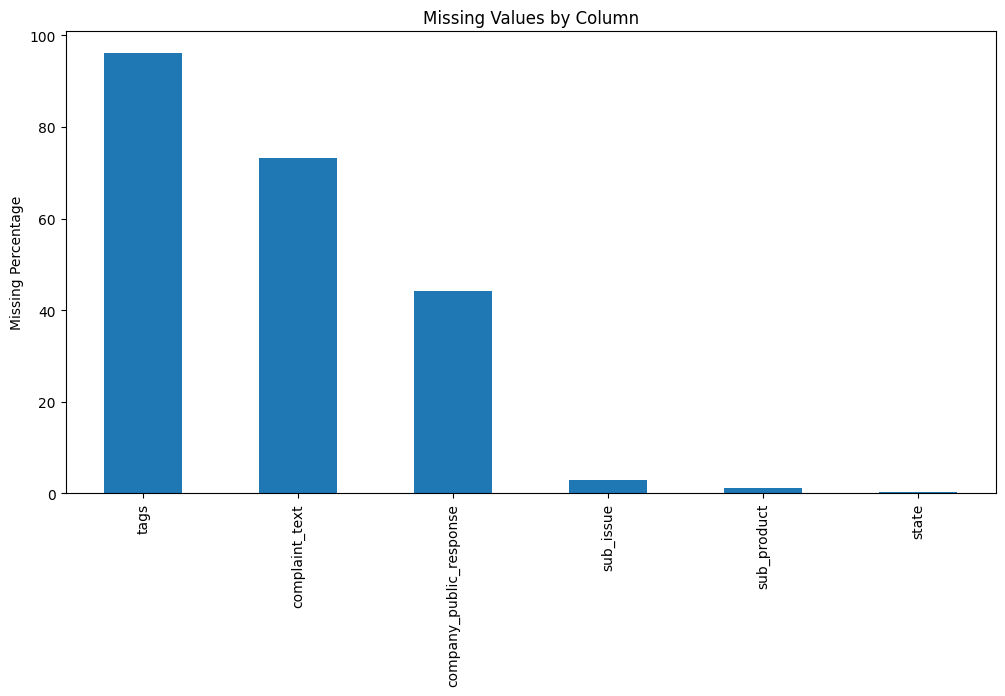

In [ ]:
plt.figure(figsize=(12,6))
missing_percent = (
    df.isnull().mean() * 100
).sort_values(ascending=False)
missing_percent[missing_percent > 0].plot(kind="bar")
plt.title("Missing Values by Column")
plt.ylabel("Missing Percentage")
plt.xticks(rotation=90)
plt.show()

Check narrative availability

In [ ]:
print(df["has_narrative"].value_counts(dropna=False))

has_narrative
False    7327
True     2673
Name: count, dtype: int64


In [ ]:
print(
    "Non-empty complaint narratives:",
    df["complaint_text"].fillna("").str.strip().ne("").sum()
)

Non-empty complaint narratives: 2673


In [ ]:
narrative_percentage = (
    df["complaint_text"].fillna("").str.strip().ne("").mean() * 100
)

print(f"Narrative availability: {narrative_percentage:.2f}%")

Narrative availability: 26.73%


In [ ]:
df["complaint_text"] = df["complaint_text"].fillna("")

In [ ]:
def clean_text(text):
    text = str(text)
    text = text.lower()
    text = re.sub(r"\s+", " ", text)
    text = re.sub(r"[^a-zA-Z0-9\s]", " ", text)
    return text.strip()

In [ ]:
df["clean_text"] = df["complaint_text"].apply(clean_text)

In [ ]:
df_nlp = df[
    df["clean_text"].str.strip() != ""
].copy()

print("NLP dataset:", df_nlp.shape)

NLP dataset: (2673, 23)


In [ ]:
df_nlp["char_count"] = df_nlp["clean_text"].str.len()

In [ ]:
df_nlp[
    ["complaint_text", "clean_text"]
].head()

,complaint_text,clean_text
9,Chae bank called me about a fraudulent case ap...,chae bank called me about a fraudulent case ap...
10,The inclusion of these unauthorized accounts a...,the inclusion of these unauthorized accounts a...
15,I respectfully seek your comprehension regardi...,i respectfully seek your comprehension regardi...
17,"Upon reviewing my credit report, I identified ...",upon reviewing my credit report i identified ...
20,sent letters to aargon agency asking for valid...,sent letters to aargon agency asking for valid...


Remove Extremely Short Complaints

In [ ]:
df_nlp["word_count"] = (
    df_nlp["clean_text"]
    .str.split()
    .str.len()
)

In [ ]:
df_nlp = df_nlp[
    df_nlp["word_count"] >= 5
].copy()

print(df_nlp.shape)

(2671, 25)


Complaint Text Statistics

In [ ]:
df_nlp["char_count"] = (
    df_nlp["clean_text"]
    .str.len()
)

In [ ]:
df_nlp[
    ["char_count", "word_count"]
].describe()

,char_count,word_count
count,2671.000000,2671.000000
mean,987.152377,167.055410
std,1296.578205,212.468696
min,46.000000,6.000000
25%,324.000000,58.000000
50%,609.000000,103.000000
75%,1043.000000,180.000000
max,18790.000000,3084.000000


Word count

In [ ]:
df_nlp["word_count"] = (
    df_nlp["clean_text"]
    .str.split()
    .str.len()
)

In [ ]:
df_nlp[[
    "clean_text",
    "char_count",
    "word_count"
]].head()

,clean_text,char_count,word_count
9,chae bank called me about a fraudulent case ap...,216,40
10,the inclusion of these unauthorized accounts a...,457,68
15,i respectfully seek your comprehension regardi...,285,48
17,upon reviewing my credit report i identified ...,126,20
20,sent letters to aargon agency asking for valid...,660,128


Complaint length visualization(Word count)

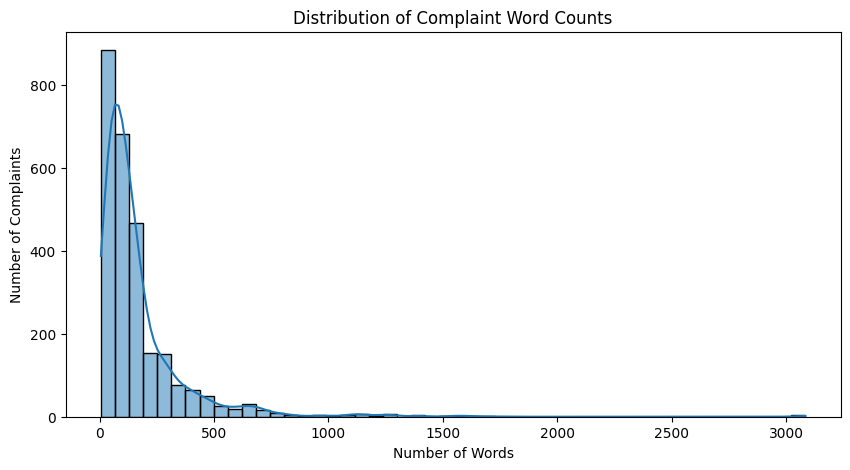

In [ ]:
plt.figure(figsize=(10,5))

sns.histplot(
    df_nlp["word_count"],
    bins=50,
    kde=True,
)
plt.title("Distribution of Complaint Word Counts")
plt.xlabel("Number of Words")
plt.ylabel("Number of Complaints")
plt.show()

Boxplot

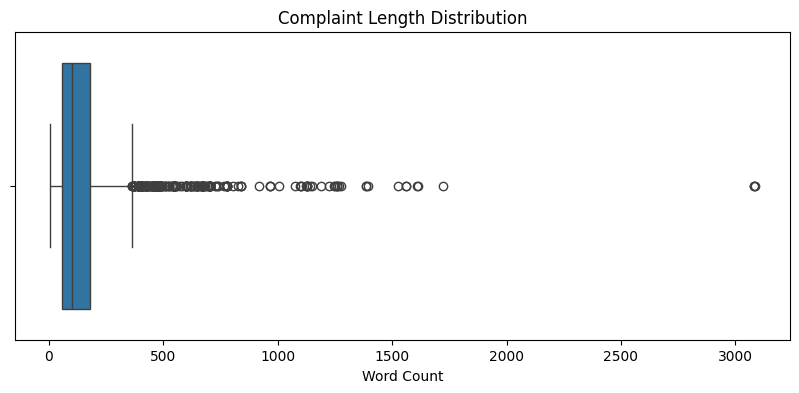

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(10,4))
sns.boxplot(
    x=df_nlp["word_count"]
)

plt.title("Complaint Length Distribution")
plt.xlabel("Word Count")
plt.show()

Most common words

In [ ]:
from collections import Counter

all_words = " ".join(
    df_nlp["clean_text"]
).split()

word_counts = Counter(
    all_words
)

common_words = pd.DataFrame(
    word_counts.most_common(20),
    columns=[
        "Word",
        "Frequency"
    ]
)

common_words

,Word,Frequency
0,xxxx,32955
1,the,18405
2,to,12927
3,and,10603
4,of,10594
5,my,10435
6,i,9957
7,a,9558
8,credit,6438
9,this,5946


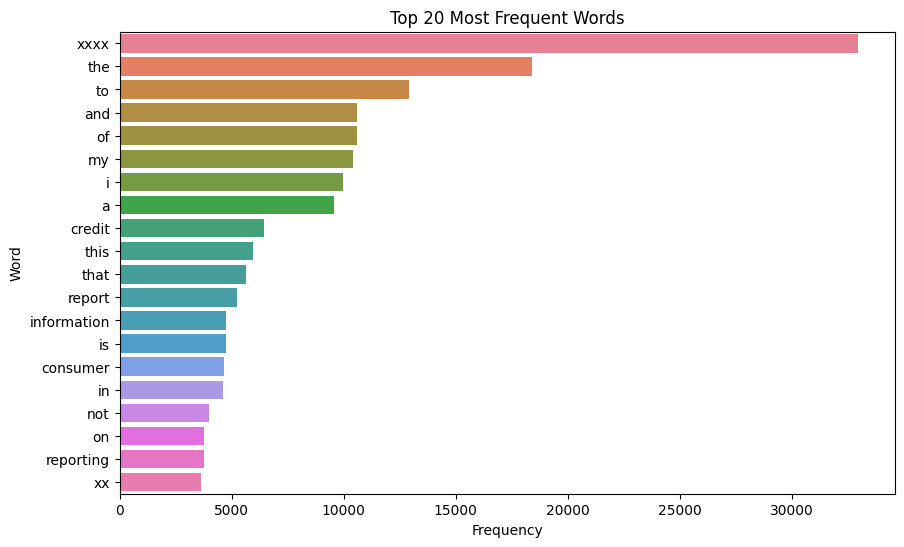

In [ ]:
plt.figure(figsize=(10,6))
sns.barplot(
    data=common_words,
    x="Frequency",
    y="Word",
    palette="husl"
)
plt.title("Top 20 Most Frequent Words")
plt.show()

Word cloud

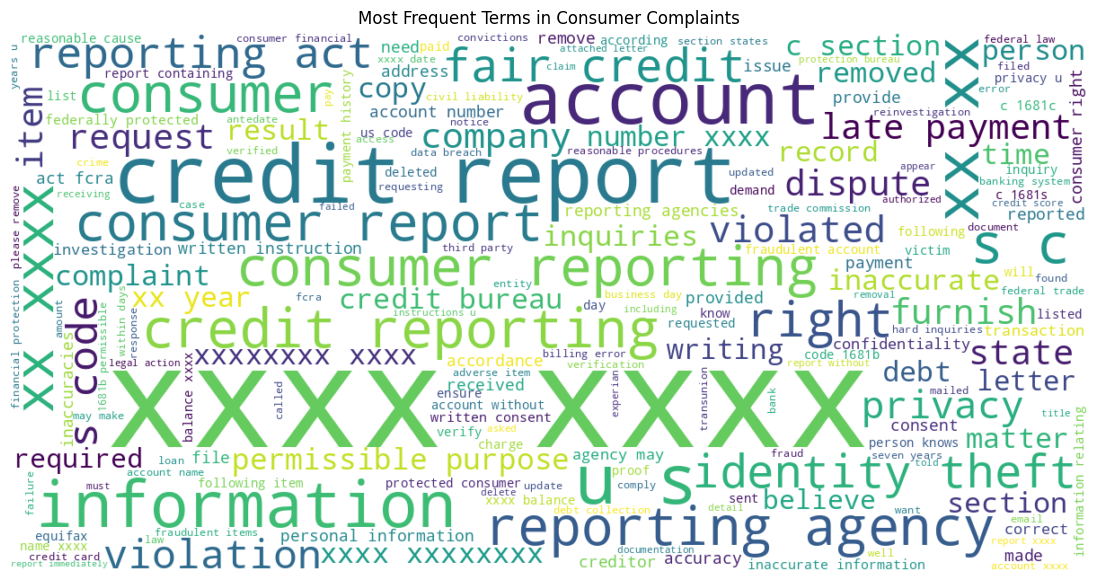

In [ ]:
from wordcloud import WordCloud

all_text = " ".join(
    df_nlp["clean_text"].sample(
        min(10000, len(df_nlp)),
        random_state=42
    )
)

wordcloud = WordCloud(
    width=1200,
    height=600,
    background_color="White"
).generate(all_text)

plt.figure(figsize=(15,7))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("Most Frequent Terms in Consumer Complaints")
plt.show()

Product-wise complaint analysis

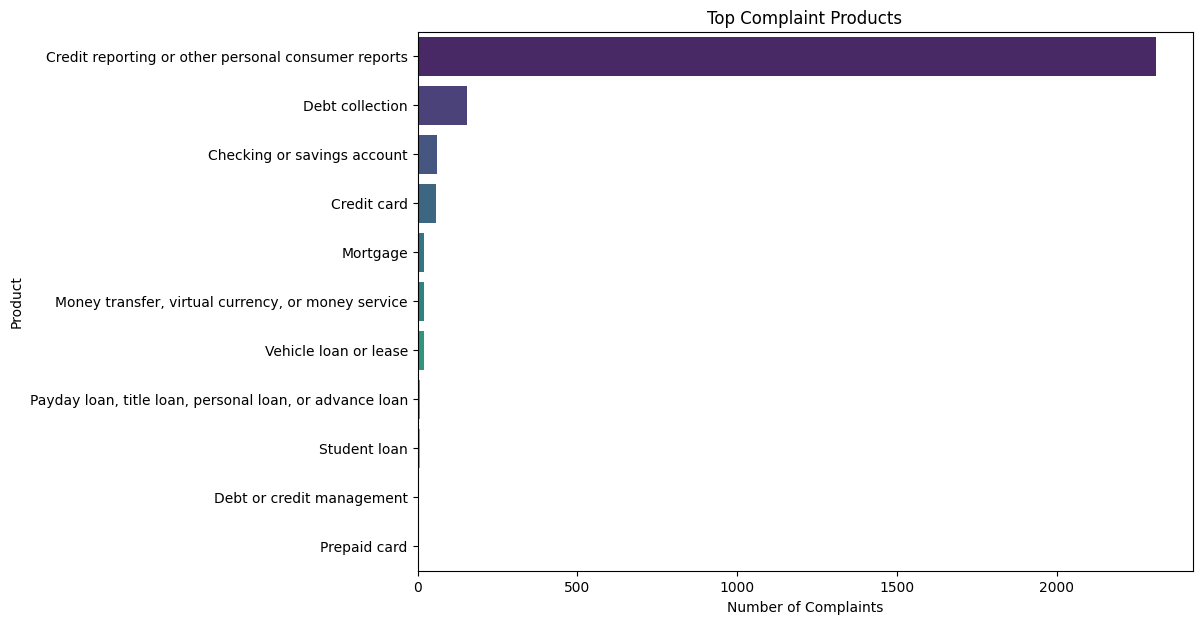

In [ ]:
product_counts = (
    df_nlp["product"]
    .value_counts()
    .head(15)
)

plt.figure(figsize=(10,7))

sns.barplot(
    x=product_counts.values,
    y=product_counts.index,
    palette="viridis"
)

plt.title("Top Complaint Products")
plt.xlabel("Number of Complaints")
plt.ylabel("Product")

plt.show()

Issue Analysis

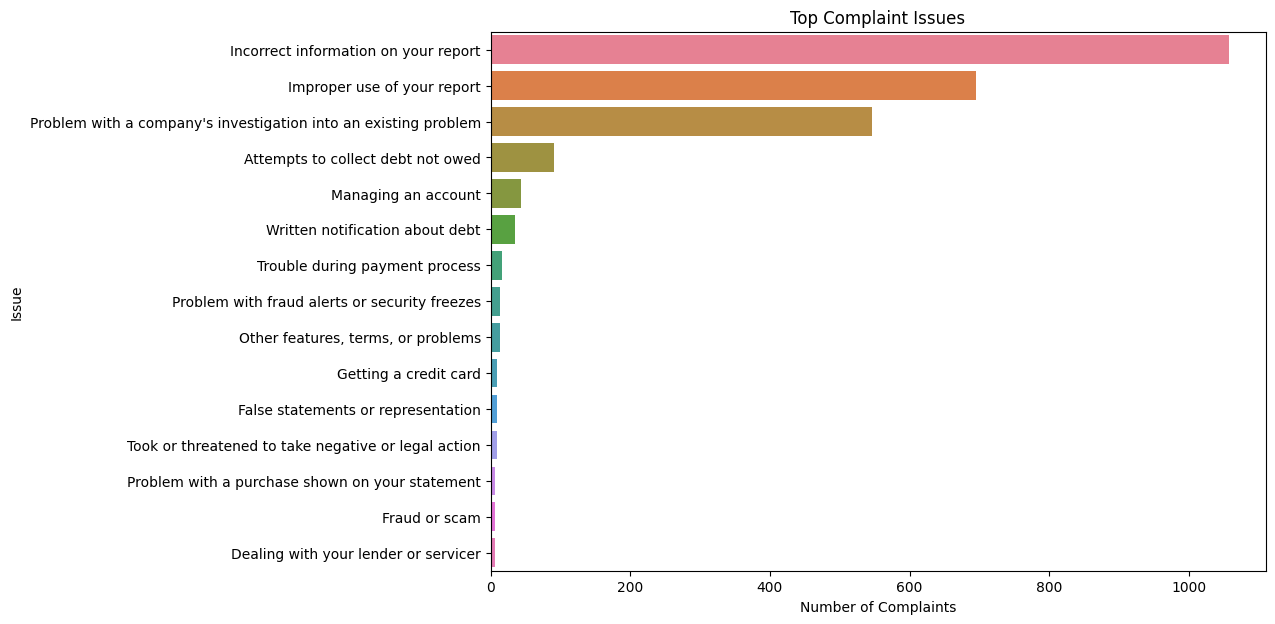

In [ ]:
issue_counts = (
    df_nlp["issue"]
    .value_counts()
    .head(15)
)

plt.figure(figsize=(10,7))

sns.barplot(
    x=issue_counts.values,
    y=issue_counts.index,
    palette="husl"
)

plt.title(
    "Top Complaint Issues"
)

plt.xlabel("Number of Complaints")

plt.ylabel("Issue")

plt.show()

Sub-Issue Analysis

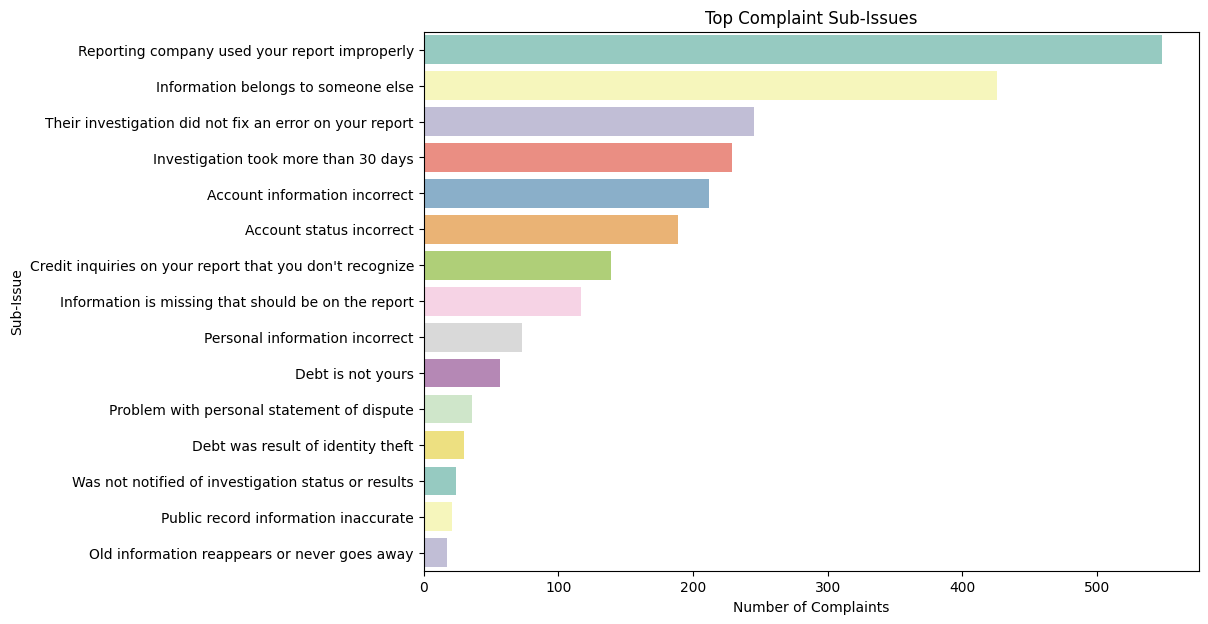

In [ ]:
subissue_counts = (
    df_nlp["sub_issue"]
    .value_counts()
    .head(15)
)

plt.figure(figsize=(10,7))

sns.barplot(
    x=subissue_counts.values,
    y=subissue_counts.index,
    palette="Set3"
)

plt.title(
    "Top Complaint Sub-Issues"
)

plt.xlabel("Number of Complaints")

plt.ylabel("Sub-Issue")

plt.show()

Resolution Analysis

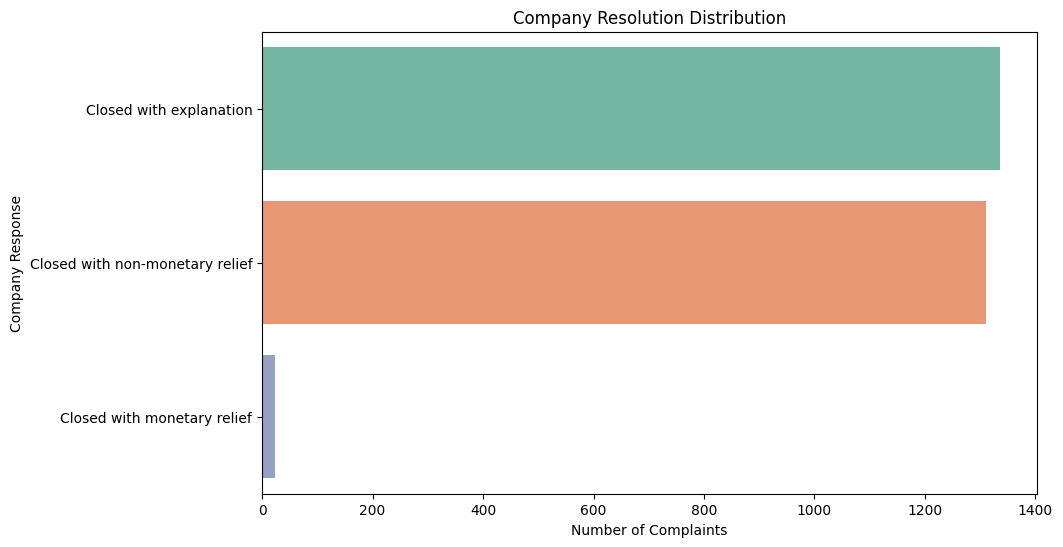

In [ ]:
response_counts = (
    df_nlp["company_response"]
    .value_counts()
)

response_counts
plt.figure(figsize=(10,6))

sns.barplot(
    x=response_counts.values,
    y=response_counts.index,
    palette="Set2"
)

plt.title(
    "Company Resolution Distribution"
)

plt.xlabel("Number of Complaints")

plt.ylabel("Company Response")

plt.show()

TF-IDF Baseline

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

In [ ]:
tfidf = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1,2),
    min_df=2
)
X_text = tfidf.fit_transform(
    df_nlp["clean_text"]
)

y = df_nlp[
    "company_response"
]

Remove Very Rare Resolution Classes

In [ ]:
response_counts = (
    y.value_counts()
)

valid_classes = response_counts[
    response_counts >= 10
].index

model_df = df_nlp[
    df_nlp["company_response"]
    .isin(valid_classes)
].copy()
X_text = tfidf.fit_transform(
    model_df["clean_text"]
)

y = model_df[
    "company_response"
]

Train/Test Split

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_text,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

Logistic Regression(Baseline)

In [ ]:
from sklearn.linear_model import LogisticRegression
lr_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced"
)

lr_model.fit(
    X_train,
    y_train
)

LogisticRegression(class_weight='balanced', max_iter=1000)

In [ ]:
y_pred_lr = lr_model.predict(
    X_test
)
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

print(
    "Accuracy:",
    accuracy_score(
        y_test,
        y_pred_lr
    )
)

print(
    classification_report(
        y_test,
        y_pred_lr
    )
)

Accuracy: 0.611214953271028
                                 precision    recall  f1-score   support

        Closed with explanation       0.62      0.57      0.60       268
    Closed with monetary relief       0.14      0.20      0.17         5
Closed with non-monetary relief       0.61      0.66      0.63       262

                       accuracy                           0.61       535
                      macro avg       0.46      0.48      0.47       535
                   weighted avg       0.61      0.61      0.61       535



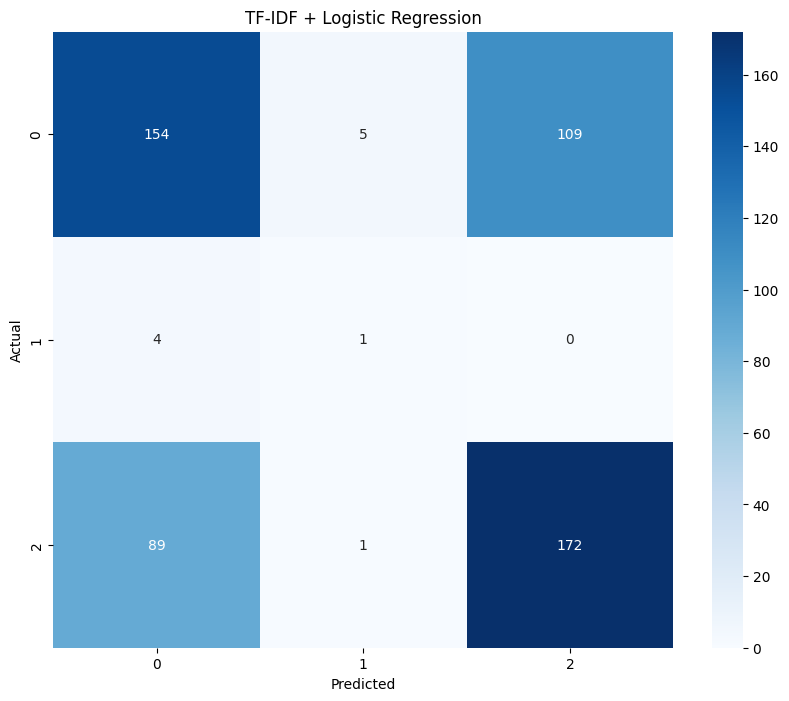

In [ ]:
cm = confusion_matrix(
    y_test,
    y_pred_lr
)

plt.figure(figsize=(10,8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title(
    "TF-IDF + Logistic Regression"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [ ]:
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# ---------------------------------------------------------
# TF-IDF + LINEAR SVM
# ---------------------------------------------------------

svm_model = LinearSVC(
    random_state=42,
    class_weight="balanced"
)

svm_model.fit(
    X_train,
    y_train
)

# Prediction
y_pred_svm = svm_model.predict(
    X_test
)

# Metrics
svm_accuracy = accuracy_score(
    y_test,
    y_pred_svm
)

svm_precision = precision_score(
    y_test,
    y_pred_svm,
    average="macro",
    zero_division=0
)

svm_recall = recall_score(
    y_test,
    y_pred_svm,
    average="macro",
    zero_division=0
)

svm_f1 = f1_score(
    y_test,
    y_pred_svm,
    average="macro",
    zero_division=0
)

print("TF-IDF + Linear SVM")
print("=" * 50)
print("Accuracy :", round(svm_accuracy, 4))
print("Precision:", round(svm_precision, 4))
print("Recall   :", round(svm_recall, 4))
print("Macro F1 :", round(svm_f1, 4))

TF-IDF + Linear SVM
Accuracy : 0.6486
Precision: 0.4336
Recall   : 0.4368
Macro F1 : 0.4346


**TF-IDF + Random Forest**

In [ ]:
from sklearn.ensemble import RandomForestClassifier

# ---------------------------------------------------------
# TF-IDF + RANDOM FOREST
# ---------------------------------------------------------

rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

rf_model.fit(
    X_train,
    y_train
)

# Prediction
y_pred_rf = rf_model.predict(
    X_test
)

# Metrics
rf_accuracy = accuracy_score(
    y_test,
    y_pred_rf
)

rf_precision = precision_score(
    y_test,
    y_pred_rf,
    average="macro",
    zero_division=0
)

rf_recall = recall_score(
    y_test,
    y_pred_rf,
    average="macro",
    zero_division=0
)

rf_f1 = f1_score(
    y_test,
    y_pred_rf,
    average="macro",
    zero_division=0
)

print("TF-IDF + Random Forest")
print("=" * 50)
print("Accuracy :", round(rf_accuracy, 4))
print("Precision:", round(rf_precision, 4))
print("Recall   :", round(rf_recall, 4))
print("Macro F1 :", round(rf_f1, 4))

TF-IDF + Random Forest
Accuracy : 0.6206
Precision: 0.4138
Recall   : 0.4175
Macro F1 : 0.4156


complete classification baseline table

In [ ]:
classification_baselines = pd.DataFrame({

    "Model": [
        "TF-IDF + Logistic Regression",
        "TF-IDF + Linear SVM",
        "TF-IDF + Random Forest"
    ],

    "Accuracy": [
        accuracy_score(y_test, y_pred_lr),
        svm_accuracy,
        rf_accuracy
    ],

    "Macro Precision": [
        precision_score(
            y_test,
            y_pred_lr,
            average="macro",
            zero_division=0
        ),
        svm_precision,
        rf_precision
    ],

    "Macro Recall": [
        recall_score(
            y_test,
            y_pred_lr,
            average="macro",
            zero_division=0
        ),
        svm_recall,
        rf_recall
    ],

    "Macro F1": [
        f1_score(
            y_test,
            y_pred_lr,
            average="macro",
            zero_division=0
        ),
        svm_f1,
        rf_f1
    ]
})

classification_baselines = (
    classification_baselines
    .round(4)
)

display(classification_baselines)

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1
0,TF-IDF + Logistic Regression,0.6112,0.4595,0.4770,0.4661
1,TF-IDF + Linear SVM,0.6486,0.4336,0.4368,0.4346
2,TF-IDF + Random Forest,0.6206,0.4138,0.4175,0.4156


TRANSFORMER MODEL

In [ ]:
from sentence_transformers import SentenceTransformer

In [ ]:
embedding_model = SentenceTransformer(
    "all-MiniLM-L6-v2"
)
print("Transformer model loaded")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Transformer model loaded


Generate embeddings

In [ ]:
sample_texts = df_nlp["clean_text"].head(1000).tolist()
embeddings = embedding_model.encode(
    sample_texts,
    batch_size=32,
    show_progress_bar=True,
    convert_to_numpy=True
)

print(
    "Embedding shape:",
    embeddings.shape
)
print("Embedding shape:", embeddings.shape)

Batches:   0%|          | 0/32 [00:00<?, ?it/s]

Embedding shape: (1000, 384)
Embedding shape: (1000, 384)


Save Embeddings

In [ ]:
np.save(
    "complaint_embeddings.npy",
    embeddings
)

Semantic Similarity

In [ ]:
from sklearn.metrics.pairwise import cosine_similarity

In [ ]:
def semantic_search(
    query,
    top_k=5
):

    query_clean = clean_text(
        query
    )

    query_embedding = (
        embedding_model.encode(
            [query_clean]
        )
    )

    similarity = cosine_similarity(
        query_embedding,
        embeddings
    )[0]

    top_indices = np.argsort(
        similarity
    )[::-1][:top_k]

    results = df_nlp.iloc[
        top_indices
    ].copy()

    results[
        "similarity_score"
    ] = similarity[
        top_indices
    ]

    return results

Test Semantic Search

In [ ]:
query = """
I found an unauthorized inquiry
on my credit report that I do not recognize.
"""

In [ ]:
results = semantic_search(
    query,
    top_k=5
)
results[[
    "complaint_text",
    "product",
    "issue",
    "sub_issue",
    "company_response",
    "similarity_score"
]]

,complaint_text,product,issue,sub_issue,company_response,similarity_score
3043,There's an inquiry on my credit report that I ...,Credit reporting or other personal consumer re...,Improper use of your report,Credit inquiries on your report that you don't...,Closed with explanation,0.822083
1484,Good day. There's an inquiry on my credit repo...,Credit reporting or other personal consumer re...,Improper use of your report,Credit inquiries on your report that you don't...,Closed with explanation,0.796845
1318,Good day. There's inquiries on my credit repor...,Credit reporting or other personal consumer re...,Improper use of your report,Credit inquiries on your report that you don't...,Closed with explanation,0.790996
2137,"Tonight, I found unauthorized inquiries on my ...",Credit reporting or other personal consumer re...,Improper use of your report,Credit inquiries on your report that you don't...,Closed with explanation,0.785892
1360,This is very alarming and concerning as there'...,Credit reporting or other personal consumer re...,Improper use of your report,Credit inquiries on your report that you don't...,Closed with explanation,0.779472


FAISS

In [ ]:
try:
    import faiss
except ImportError:
    !pip install faiss-cpu
    import faiss

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.8/18.8 MB 33.9 MB/s eta 0:00:00


In [ ]:
embedding_matrix = (
    embeddings
    .astype("float32")
)
faiss.normalize_L2(
    embedding_matrix
)
dimension = (
    embedding_matrix.shape[1]
)

index = faiss.IndexFlatIP(
    dimension
)

index.add(
    embedding_matrix
)

print(
    "Indexed complaints:",
    index.ntotal
)

Indexed complaints: 1000


FAISS Search Function

In [ ]:
def faiss_search(
    query,
    top_k=5
):

    query_clean = clean_text(
        query
    )

    query_embedding = (
        embedding_model.encode(
            [query_clean]
        )
        .astype("float32")
    )

    faiss.normalize_L2(
        query_embedding
    )

    scores, indices = index.search(
        query_embedding,
        top_k
    )

    results = df_nlp.iloc[
        indices[0]
    ].copy()

    results[
        "similarity_score"
    ] = scores[0]

    return results

In [ ]:
similar_cases = faiss_search(
    query,
    top_k=1000
)

final_retrieval_output = similar_cases[[
    "complaint_id",
    "complaint_text",
    "product",
    "sub_product",
    "issue",
    "sub_issue",
    "company",
    "company_response",
    "similarity_score"
]]

final_retrieval_output

,complaint_id,complaint_text,product,sub_product,issue,sub_issue,company,company_response,similarity_score
3043,9996796,There's an inquiry on my credit report that I ...,Credit reporting or other personal consumer re...,Credit reporting,Improper use of your report,Credit inquiries on your report that you don't...,"EQUIFAX, INC.",Closed with explanation,0.822083
1484,9998392,Good day. There's an inquiry on my credit repo...,Credit reporting or other personal consumer re...,Credit reporting,Improper use of your report,Credit inquiries on your report that you don't...,"TRANSUNION INTERMEDIATE HOLDINGS, INC.",Closed with explanation,0.796845
1318,9998592,Good day. There's inquiries on my credit repor...,Credit reporting or other personal consumer re...,Credit reporting,Improper use of your report,Credit inquiries on your report that you don't...,Experian Information Solutions Inc.,Closed with explanation,0.790996
2137,9997724,"Tonight, I found unauthorized inquiries on my ...",Credit reporting or other personal consumer re...,Credit reporting,Improper use of your report,Credit inquiries on your report that you don't...,"EQUIFAX, INC.",Closed with explanation,0.785892
1360,9998541,This is very alarming and concerning as there'...,Credit reporting or other personal consumer re...,Credit reporting,Improper use of your report,Credit inquiries on your report that you don't...,"EQUIFAX, INC.",Closed with explanation,0.779472
...,...,...,...,...,...,...,...,...,...
1139,9998785,Could you please take a moment to review and e...,Credit reporting or other personal consumer re...,Credit reporting,Incorrect information on your report,Account information incorrect,"EQUIFAX, INC.",Closed with explanation,0.150190
1133,9998792,Could you please take a moment to review and e...,Credit reporting or other personal consumer re...,Credit reporting,Incorrect information on your report,Account information incorrect,Experian Information Solutions Inc.,Closed with explanation,0.150190
1125,9998801,Could you please take a moment to review and e...,Debt collection,I do not know,Attempts to collect debt not owed,Debt was result of identity theft,"TRANSUNION INTERMEDIATE HOLDINGS, INC.",Closed with non-monetary relief,0.150190
922,9999022,Could you please take a moment to review and e...,Debt collection,I do not know,Attempts to collect debt not owed,Debt was result of identity theft,Experian Information Solutions Inc.,Closed with explanation,0.150190


MEM-2

In [ ]:


retrieved = final_retrieval_output.copy()

# Make sure similarity is numeric
retrieved["similarity_score"] = pd.to_numeric(
    retrieved["similarity_score"],
    errors="coerce"
)

# Remove invalid rows
retrieved = retrieved.dropna(
    subset=["similarity_score", "company_response"]
)

# Sort by semantic similarity
retrieved = retrieved.sort_values(
    "similarity_score",
    ascending=False
).reset_index(drop=True)

# Assign retrieval rank
retrieved["retrieval_rank"] = (
    retrieved.index + 1
)

display(
    retrieved[
        [
            "complaint_id",
            "product",
            "issue",
            "sub_issue",
            "company_response",
            "similarity_score",
            "retrieval_rank"
        ]
    ]
)

,complaint_id,product,issue,sub_issue,company_response,similarity_score,retrieval_rank
0,9996796,Credit reporting or other personal consumer re...,Improper use of your report,Credit inquiries on your report that you don't...,Closed with explanation,0.822083,1
1,9998392,Credit reporting or other personal consumer re...,Improper use of your report,Credit inquiries on your report that you don't...,Closed with explanation,0.796845,2
2,9998592,Credit reporting or other personal consumer re...,Improper use of your report,Credit inquiries on your report that you don't...,Closed with explanation,0.790996,3
3,9997724,Credit reporting or other personal consumer re...,Improper use of your report,Credit inquiries on your report that you don't...,Closed with explanation,0.785892,4
4,9998541,Credit reporting or other personal consumer re...,Improper use of your report,Credit inquiries on your report that you don't...,Closed with explanation,0.779472,5
...,...,...,...,...,...,...,...
995,9997044,Debt collection,Attempts to collect debt not owed,Debt was result of identity theft,Closed with explanation,0.150190,996
996,9998792,Credit reporting or other personal consumer re...,Incorrect information on your report,Account information incorrect,Closed with explanation,0.150190,997
997,9998801,Debt collection,Attempts to collect debt not owed,Debt was result of identity theft,Closed with non-monetary relief,0.150190,998
998,9999022,Debt collection,Attempts to collect debt not owed,Debt was result of identity theft,Closed with explanation,0.150190,999


 Find the original query record

In [ ]:

query_row = similar_cases.iloc[0]

print("Query complaint:")
print(query_row["complaint_text"])

print("\nQuery context:")
print("Product    :", query_row["product"])
print("Sub-product:", query_row["sub_product"])
print("Issue      :", query_row["issue"])
print("Sub-issue  :", query_row["sub_issue"])
print("Company    :", query_row["company"])


Query complaint:
There's an inquiry on my credit report that I don't recognize, I did not authorize this nor given consent to the company to pull up my credit report. It is stressing me and making me anxious on why and how this happened.

Query context:
Product    : Credit reporting or other personal consumer reports
Sub-product: Credit reporting
Issue      : Improper use of your report
Sub-issue  : Credit inquiries on your report that you don't recognize
Company    : EQUIFAX, INC.


Calculate Context Similarity

In [ ]:


context_weights = {
    "product": 0.25,
    "sub_product": 0.15,
    "issue": 0.25,
    "sub_issue": 0.20,
    "company": 0.10,
    "timely": 0.05
}

def calculate_context_similarity(query_row, retrieved_row):

    score = 0.0

    for feature, weight in context_weights.items():

        query_value = str(
            query_row[feature]
        ).strip().lower()

        retrieved_value = str(
            retrieved_row[feature]
        ).strip().lower()

        if query_value == retrieved_value:
            score += weight

    return score

In [ ]:

retrieved = final_retrieval_output.copy().merge(
    df_nlp[['complaint_id', 'timely']],
    on='complaint_id',
    how='left'
)

# Now, calculate context_similarity with the 'timely' column present.
retrieved["context_similarity"] = retrieved.apply(
    lambda row:
    calculate_context_similarity(
        query_row,
        row
    ),
    axis=1
)

display(
    retrieved[
        [
            "complaint_id",
            "product",
            "issue",
            "sub_issue",
            "similarity_score",
            "context_similarity"
        ]
    ]
)

,complaint_id,product,issue,sub_issue,similarity_score,context_similarity
0,9996796,Credit reporting or other personal consumer re...,Improper use of your report,Credit inquiries on your report that you don't...,0.822083,1.00
1,9998392,Credit reporting or other personal consumer re...,Improper use of your report,Credit inquiries on your report that you don't...,0.796845,0.90
2,9998592,Credit reporting or other personal consumer re...,Improper use of your report,Credit inquiries on your report that you don't...,0.790996,0.90
3,9997724,Credit reporting or other personal consumer re...,Improper use of your report,Credit inquiries on your report that you don't...,0.785892,1.00
4,9998541,Credit reporting or other personal consumer re...,Improper use of your report,Credit inquiries on your report that you don't...,0.779472,1.00
...,...,...,...,...,...,...
995,9998785,Credit reporting or other personal consumer re...,Incorrect information on your report,Account information incorrect,0.150190,0.55
996,9998792,Credit reporting or other personal consumer re...,Incorrect information on your report,Account information incorrect,0.150190,0.45
997,9998801,Debt collection,Attempts to collect debt not owed,Debt was result of identity theft,0.150190,0.05
998,9999022,Debt collection,Attempts to collect debt not owed,Debt was result of identity theft,0.150190,0.05


Hybrid / Context-Aware Score

HybridScore=0.7(SemanticSimilarity)+0.3(ContextSimilarity)

In [ ]:

SEMANTIC_WEIGHT = 0.70
CONTEXT_WEIGHT = 0.30

retrieved["hybrid_score"] = (
    SEMANTIC_WEIGHT *
    retrieved["similarity_score"]
    +
    CONTEXT_WEIGHT *
    retrieved["context_similarity"]
)

retrieved = retrieved.sort_values(
    "hybrid_score",
    ascending=False
).reset_index(drop=True)

retrieved["context_rank"] = (
    retrieved.index + 1
)

display(
    retrieved[
        [
            "complaint_id",
            "similarity_score",
            "context_similarity",
            "hybrid_score",
            "context_rank",
            "company_response"
        ]
    ]
)

,complaint_id,similarity_score,context_similarity,hybrid_score,context_rank,company_response
0,9996796,0.822083,1.00,0.875458,1,Closed with explanation
1,9997724,0.785892,1.00,0.850124,2,Closed with explanation
2,9998541,0.779472,1.00,0.845631,3,Closed with explanation
3,9996749,0.777194,1.00,0.844036,4,Closed with non-monetary relief
4,9998392,0.796845,0.90,0.827791,5,Closed with explanation
...,...,...,...,...,...,...
995,9998319,0.150190,0.15,0.150133,996,Closed with explanation
996,9998318,0.150190,0.05,0.120133,997,Closed with explanation
997,9998801,0.150190,0.05,0.120133,998,Closed with non-monetary relief
998,9999022,0.150190,0.05,0.120133,999,Closed with explanation


#Baseline Comparison

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity


eval_df = df_nlp.head(1000).copy().reset_index(drop=True)

# Make sure text is available
eval_df["clean_text"] = eval_df["clean_text"].fillna("").astype(str)

print("Evaluation records:", len(eval_df))
print("Embedding shape:", embeddings.shape)

# ---------------------------------------------------------
# TF-IDF BASELINE
# ---------------------------------------------------------

tfidf_vectorizer = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2),
    min_df=2
)

tfidf_matrix = tfidf_vectorizer.fit_transform(
    eval_df["clean_text"]
)

print("TF-IDF matrix shape:", tfidf_matrix.shape)

Evaluation records: 1000
Embedding shape: (1000, 384)
TF-IDF matrix shape: (1000, 10000)


In [ ]:
# ---------------------------------------------------------
# Normalize SBERT EMBEDDINGS
# ---------------------------------------------------------

sbert_embeddings = embeddings.copy().astype("float32")

# Normalize for cosine similarity
norms = np.linalg.norm(sbert_embeddings, axis=1, keepdims=True)
sbert_embeddings = sbert_embeddings / np.maximum(norms, 1e-12)

print("SBERT embeddings:", sbert_embeddings.shape)

SBERT embeddings: (1000, 384)


In [ ]:
# ---------------------------------------------------------
# CONTEXT SIMILARITY
# ---------------------------------------------------------

def context_similarity(query_row, candidate_df):
    """
    Calculate weighted context similarity between
    one query complaint and all candidate complaints.
    """

    scores = np.zeros(len(candidate_df))

    for feature, weight in context_weights.items():

        query_value = str(
            query_row[feature]
        ).strip().lower()

        candidate_values = (
            candidate_df[feature]
            .fillna("")
            .astype(str)
            .str.strip()
            .str.lower()
            .values
        )

        scores += (
            candidate_values == query_value
        ).astype(float) * weight

    return scores

In [ ]:
# ---------------------------------------------------------
# RELEVANCE CRITERION
# ---------------------------------------------------------

def relevance_mask(query_row, candidate_df):

    query_product = str(
        query_row["product"]
    ).strip().lower()

    query_issue = str(
        query_row["issue"]
    ).strip().lower()

    candidate_product = (
        candidate_df["product"]
        .fillna("")
        .astype(str)
        .str.strip()
        .str.lower()
    )

    candidate_issue = (
        candidate_df["issue"]
        .fillna("")
        .astype(str)
        .str.strip()
        .str.lower()
    )

    return (
        (candidate_product == query_product) &
        (candidate_issue == query_issue)
    ).values

In [ ]:
# ---------------------------------------------------------
# RETRIEVAL METRICS
# ---------------------------------------------------------

def precision_at_k(relevant, k=10):

    top_k = relevant[:k]

    if len(top_k) == 0:
        return 0.0

    return np.sum(top_k) / k


def recall_at_k(relevant, total_relevant, k=10):

    if total_relevant == 0:
        return 0.0

    return np.sum(relevant[:k]) / total_relevant


def reciprocal_rank(relevant):

    for rank, value in enumerate(relevant, start=1):

        if value:
            return 1.0 / rank

    return 0.0


def ndcg_at_k(relevant, k=10):

    relevance = np.asarray(
        relevant[:k],
        dtype=float
    )

    if len(relevance) == 0:
        return 0.0

    discounts = np.log2(
        np.arange(2, len(relevance) + 2)
    )

    dcg = np.sum(
        relevance / discounts
    )

    ideal = np.sort(
        relevance
    )[::-1]

    idcg = np.sum(
        ideal / discounts
    )

    if idcg == 0:
        return 0.0

    return dcg / idcg

In [ ]:
# ---------------------------------------------------------
# SELECT MULTIPLE EVALUATION QUERIES
# ---------------------------------------------------------

np.random.seed(42)

N_QUERIES = 100

query_indices = np.random.choice(
    len(eval_df),
    size=N_QUERIES,
    replace=False
)

print("Number of evaluation queries:", len(query_indices))

Number of evaluation queries: 100


In [ ]:
# ---------------------------------------------------------
# BASELINE COMPARISON
# ---------------------------------------------------------

TOP_K = 10

results = []

for q_idx in query_indices:

    query_row = eval_df.iloc[q_idx]

    # =====================================================
    # 1. TF-IDF COSINE BASELINE
    # =====================================================

    tfidf_query = tfidf_matrix[q_idx]

    tfidf_scores = cosine_similarity(
        tfidf_query,
        tfidf_matrix
    )[0]

    # Remove query itself
    tfidf_scores[q_idx] = -np.inf

    tfidf_ranking = np.argsort(
        tfidf_scores
    )[::-1]

    tfidf_relevance_all = relevance_mask(
        query_row,
        eval_df.iloc[tfidf_ranking]
    )

    total_relevant = np.sum(
        relevance_mask(
            query_row,
            eval_df.drop(index=q_idx)
        )
    )

    tfidf_relevance_top = (
        tfidf_relevance_all[:TOP_K]
    )

    results.append({
        "query_index": q_idx,
        "method": "TF-IDF + Cosine",
        "Precision@10": precision_at_k(
            tfidf_relevance_all,
            TOP_K
        ),
        "Recall@10": recall_at_k(
            tfidf_relevance_all,
            total_relevant,
            TOP_K
        ),
        "MRR": reciprocal_rank(
            tfidf_relevance_all
        ),
        "nDCG@10": ndcg_at_k(
            tfidf_relevance_all,
            TOP_K
        )
    })


    # =====================================================
    # 2. SBERT COSINE BASELINE
    # =====================================================

    sbert_query = sbert_embeddings[q_idx]

    sbert_scores = np.dot(
        sbert_embeddings,
        sbert_query
    )

    # Remove query itself
    sbert_scores[q_idx] = -np.inf

    sbert_ranking = np.argsort(
        sbert_scores
    )[::-1]

    sbert_relevance_all = relevance_mask(
        query_row,
        eval_df.iloc[sbert_ranking]
    )

    sbert_relevance_top = (
        sbert_relevance_all[:TOP_K]
    )

    results.append({
        "query_index": q_idx,
        "method": "SBERT + Cosine",
        "Precision@10": precision_at_k(
            sbert_relevance_all,
            TOP_K
        ),
        "Recall@10": recall_at_k(
            sbert_relevance_all,
            total_relevant,
            TOP_K
        ),
        "MRR": reciprocal_rank(
            sbert_relevance_all
        ),
        "nDCG@10": ndcg_at_k(
            sbert_relevance_all,
            TOP_K
        )
    })


    # =====================================================
    # 3. PROPOSED HYBRID
    # =====================================================

    semantic_scores = sbert_scores.copy()

    context_scores = context_similarity(
        query_row,
        eval_df
    )

    # Remove query itself
    context_scores[q_idx] = 0.0

    hybrid_scores = (
        0.70 * semantic_scores
        +
        0.30 * context_scores
    )

    hybrid_scores[q_idx] = -np.inf

    hybrid_ranking = np.argsort(
        hybrid_scores
    )[::-1]

    hybrid_relevance_all = relevance_mask(
        query_row,
        eval_df.iloc[hybrid_ranking]
    )

    hybrid_relevance_top = (
        hybrid_relevance_all[:TOP_K]
    )

    results.append({
        "query_index": q_idx,
        "method": "Proposed Hybrid",
        "Precision@10": precision_at_k(
            hybrid_relevance_all,
            TOP_K
        ),
        "Recall@10": recall_at_k(
            hybrid_relevance_all,
            total_relevant,
            TOP_K
        ),
        "MRR": reciprocal_rank(
            hybrid_relevance_all
        ),
        "nDCG@10": ndcg_at_k(
            hybrid_relevance_all,
            TOP_K
        )
    })


results_df = pd.DataFrame(results)

print("Experiment completed!")
print(
    "Total evaluations:",
    len(results_df)
)

Experiment completed!
Total evaluations: 300


# FINAL BASELINE COMPARISON TABLE


In [ ]:


baseline_summary = (
    results_df
    .groupby("method")
    [
        [
            "Precision@10",
            "Recall@10",
            "MRR",
            "nDCG@10"
        ]
    ]
    .mean()
    .round(4)
)

print("\nBASELINE COMPARISON")
print("=" * 70)

display(
    baseline_summary
)


BASELINE COMPARISON


,Precision@10,Recall@10,MRR,nDCG@10
method,,,,
Proposed Hybrid,0.891,0.0709,0.9701,0.9661
SBERT + Cosine,0.606,0.0288,0.8833,0.8733
TF-IDF + Cosine,0.561,0.0289,0.8150,0.8329


# IMPROVEMENT OF PROPOSED HYBRID


In [ ]:


metrics = [
    "Precision@10",
    "Recall@10",
    "MRR",
    "nDCG@10"
]

improvement_rows = []

hybrid_values = baseline_summary.loc[
    "Proposed Hybrid"
]

for method in [
    "TF-IDF + Cosine",
    "SBERT + Cosine"
]:

    baseline_values = baseline_summary.loc[
        method
    ]

    row = {
        "Compared With": method
    }

    for metric in metrics:

        base = baseline_values[metric]
        proposed = hybrid_values[metric]

        if base != 0:

            improvement = (
                (proposed - base)
                / base
            ) * 100

        else:
            improvement = np.nan

        row[metric + " Improvement (%)"] = round(
            improvement,
            2
        )

    improvement_rows.append(row)


improvement_df = pd.DataFrame(
    improvement_rows
)

display(improvement_df)

,Compared With,Precision@10 Improvement (%),Recall@10 Improvement (%),MRR Improvement (%),nDCG@10 Improvement (%)
0,TF-IDF + Cosine,58.82,145.33,19.03,15.99
1,SBERT + Cosine,47.03,146.18,9.83,10.63


# BASELINE COMPARISON GRAPH


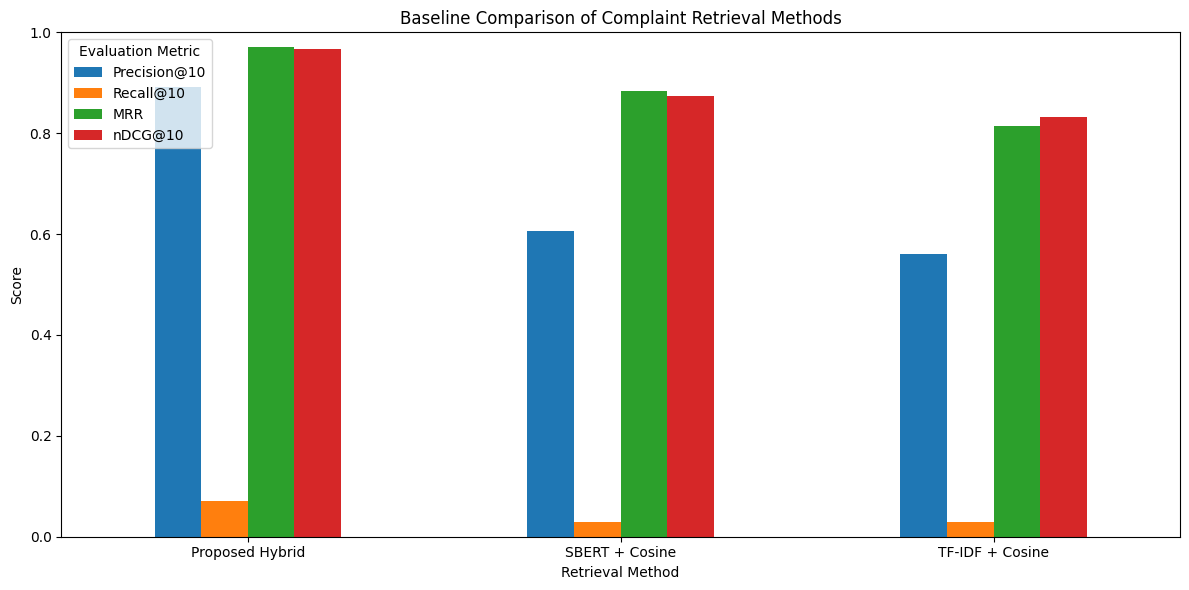

In [ ]:

plot_df = baseline_summary.copy()

ax = plot_df.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title(
    "Baseline Comparison of Complaint Retrieval Methods"
)

plt.xlabel("Retrieval Method")

plt.ylabel("Score")

plt.ylim(0, 1)

plt.xticks(
    rotation=0
)

plt.legend(
    title="Evaluation Metric"
)

plt.tight_layout()

plt.show()

#Ablation study

In [ ]:
# ============================================================
# ABLATION STUDY - CELL 1
# Prepare Evaluation Dataset
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Use the same 1000 records used for SBERT/FAISS
eval_df = df_nlp.head(1000).copy().reset_index(drop=True)

# Make sure clean text is available
eval_df["clean_text"] = (
    eval_df["clean_text"]
    .fillna("")
    .astype(str)
)

print("Number of evaluation records:", len(eval_df))
print("Embedding shape:", embeddings.shape)

Number of evaluation records: 1000
Embedding shape: (1000, 384)


In [ ]:
# ============================================================
# ABLATION STUDY - CELL 2
# Prepare SBERT Embeddings
# ============================================================

sbert_embeddings = embeddings.copy().astype("float32")

# Normalize embeddings
norms = np.linalg.norm(
    sbert_embeddings,
    axis=1,
    keepdims=True
)

sbert_embeddings = (
    sbert_embeddings /
    np.maximum(norms, 1e-12)
)

print("SBERT embeddings ready.")
print("Shape:", sbert_embeddings.shape)

SBERT embeddings ready.
Shape: (1000, 384)


In [ ]:
# ============================================================
# ABLATION STUDY - CELL 3
# Context Weights
# ============================================================

context_weights = {
    "product": 0.25,
    "sub_product": 0.15,
    "issue": 0.25,
    "sub_issue": 0.20,
    "company": 0.10,
    "timely": 0.05
}

print("Context weights:")
for feature, weight in context_weights.items():
    print(f"{feature}: {weight}")

Context weights:
product: 0.25
sub_product: 0.15
issue: 0.25
sub_issue: 0.2
company: 0.1
timely: 0.05


In [ ]:
# ============================================================
# ABLATION STUDY - CELL 4
# Context Similarity
# ============================================================

def context_similarity(query_row, candidate_df):

    scores = np.zeros(
        len(candidate_df),
        dtype=float
    )

    for feature, weight in context_weights.items():

        query_value = str(
            query_row[feature]
        ).strip().lower()

        candidate_values = (
            candidate_df[feature]
            .fillna("")
            .astype(str)
            .str.strip()
            .str.lower()
            .values
        )

        scores += (
            candidate_values == query_value
        ).astype(float) * weight

    return scores

In [ ]:
# ============================================================
# ABLATION STUDY - CELL 5
# Relevance Criterion
# ============================================================

def relevance_mask(query_row, candidate_df):

    relevance = np.ones(
        len(candidate_df),
        dtype=bool
    )

    relevance_columns = [
        "product",
        "sub_product",
        "issue",
        "sub_issue"
    ]

    for column in relevance_columns:

        query_value = str(
            query_row[column]
        ).strip().lower()

        candidate_values = (
            candidate_df[column]
            .fillna("")
            .astype(str)
            .str.strip()
            .str.lower()
            .values
        )

        relevance &= (
            candidate_values == query_value
        )

    return relevance

In [ ]:
# ============================================================
# ABLATION STUDY - CELL 5
# Relevance Criterion
# ============================================================

def relevance_mask(query_row, candidate_df):

    relevance = np.ones(
        len(candidate_df),
        dtype=bool
    )

    relevance_columns = [
        "product",
        "sub_product",
        "issue",
        "sub_issue"
    ]

    for column in relevance_columns:

        query_value = str(
            query_row[column]
        ).strip().lower()

        candidate_values = (
            candidate_df[column]
            .fillna("")
            .astype(str)
            .str.strip()
            .str.lower()
            .values
        )

        relevance &= (
            candidate_values == query_value
        )

    return relevance

In [ ]:
# ============================================================
# ABLATION STUDY - CELL 7
# Select Evaluation Queries
# ============================================================

np.random.seed(42)

N_QUERIES = 100

query_indices = np.random.choice(
    len(eval_df),
    size=N_QUERIES,
    replace=False
)

print(
    "Number of evaluation queries:",
    len(query_indices)
)

Number of evaluation queries: 100


In [ ]:
# ============================================================
# ABLATION STUDY - CELL 8
# Run Ablation Experiment
# ============================================================

TOP_K = 10

ablation_configs = {

    "Semantic Only (100:0)": {
        "semantic_weight": 1.0,
        "context_weight": 0.0
    },

    "Context Only (0:100)": {
        "semantic_weight": 0.0,
        "context_weight": 1.0
    },

    "Hybrid (50:50)": {
        "semantic_weight": 0.5,
        "context_weight": 0.5
    },

    "Proposed Hybrid (70:30)": {
        "semantic_weight": 0.7,
        "context_weight": 0.3
    }
}


ablation_results = []


for q_idx in query_indices:

    # --------------------------------------------------------
    # Query complaint
    # --------------------------------------------------------

    query_row = eval_df.iloc[q_idx]


    # --------------------------------------------------------
    # Semantic similarity
    # --------------------------------------------------------

    query_embedding = sbert_embeddings[q_idx]

    semantic_scores = np.dot(
        sbert_embeddings,
        query_embedding
    )

    # Remove the query itself
    semantic_scores[q_idx] = -np.inf


    # --------------------------------------------------------
    # Context similarity
    # --------------------------------------------------------

    context_scores = context_similarity(
        query_row,
        eval_df
    )

    # Remove query itself
    context_scores[q_idx] = 0.0


    # --------------------------------------------------------
    # Determine total relevant complaints
    # --------------------------------------------------------

    candidates_without_query = eval_df.drop(
        index=q_idx
    )

    relevant_without_query = relevance_mask(
        query_row,
        candidates_without_query
    )

    total_relevant = np.sum(
        relevant_without_query
    )


    # --------------------------------------------------------
    # Test each ablation configuration
    # --------------------------------------------------------

    for config_name, weights in ablation_configs.items():

        semantic_weight = weights[
            "semantic_weight"
        ]

        context_weight = weights[
            "context_weight"
        ]


        # -----------------------------------------------
        # Combined ranking score
        # -----------------------------------------------

        combined_scores = (
            semantic_weight *
            semantic_scores
            +
            context_weight *
            context_scores
        )


        # -----------------------------------------------
        # Rank candidates
        # -----------------------------------------------

        ranking = np.argsort(
            combined_scores
        )[::-1]


        ranked_candidates = eval_df.iloc[
            ranking
        ]


        # -----------------------------------------------
        # Determine relevance
        # -----------------------------------------------

        relevance = relevance_mask(
            query_row,
            ranked_candidates
        )


        # -----------------------------------------------
        # Metrics
        # -----------------------------------------------

        precision = precision_at_k(
            relevance,
            TOP_K
        )

        recall = recall_at_k(
            relevance,
            total_relevant,
            TOP_K
        )

        mrr = reciprocal_rank(
            relevance
        )

        ndcg = ndcg_at_k(
            relevance,
            TOP_K
        )


        # -----------------------------------------------
        # Store results
        # -----------------------------------------------

        ablation_results.append({

            "query_index": q_idx,

            "configuration": config_name,

            "semantic_weight":
                semantic_weight,

            "context_weight":
                context_weight,

            "Precision@10":
                precision,

            "Recall@10":
                recall,

            "MRR":
                mrr,

            "nDCG@10":
                ndcg
        })


ablation_results_df = pd.DataFrame(
    ablation_results
)


print("Ablation study completed!")

print(
    "Total experiment records:",
    len(ablation_results_df)
)

Ablation study completed!
Total experiment records: 400


In [ ]:
# ============================================================
# ABLATION STUDY - CELL 9
# Final Results Table
# ============================================================

ablation_summary = (
    ablation_results_df
    .groupby(
        [
            "configuration",
            "semantic_weight",
            "context_weight"
        ]
    )
    [
        [
            "Precision@10",
            "Recall@10",
            "MRR",
            "nDCG@10"
        ]
    ]
    .mean()
    .reset_index()
)


# Logical order
config_order = [
    "Semantic Only (100:0)",
    "Context Only (0:100)",
    "Hybrid (50:50)",
    "Proposed Hybrid (70:30)"
]


ablation_summary["configuration"] = pd.Categorical(
    ablation_summary["configuration"],
    categories=config_order,
    ordered=True
)


ablation_summary = (
    ablation_summary
    .sort_values("configuration")
    .reset_index(drop=True)
)


print(
    "\nABLATION STUDY RESULTS"
)

print("=" * 80)

display(
    ablation_summary.round(4)
)


ABLATION STUDY RESULTS


,configuration,semantic_weight,context_weight,Precision@10,Recall@10,MRR,nDCG@10
0,Semantic Only (100:0),1.0,0.0,0.495,0.0935,0.7973,0.7984
1,Context Only (0:100),0.0,1.0,0.926,0.2351,0.9800,0.9800
2,Hybrid (50:50),0.5,0.5,0.867,0.1768,0.9500,0.9455
3,Proposed Hybrid (70:30),0.7,0.3,0.772,0.1528,0.9308,0.9256


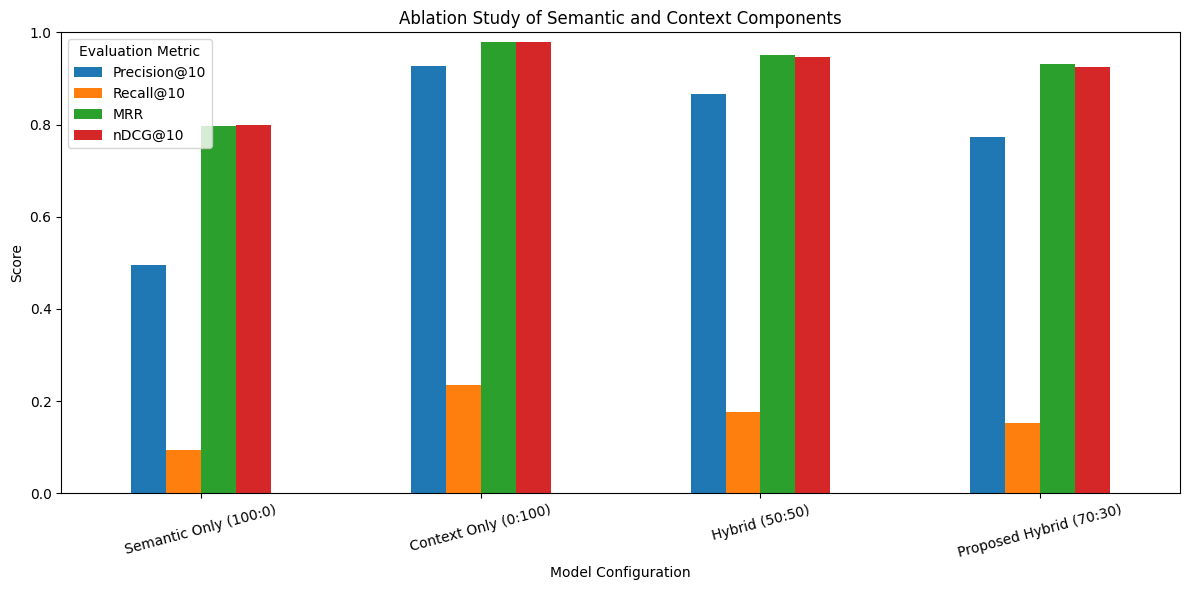

In [ ]:
# ============================================================
# ABLATION STUDY - CELL 10
# Visualization
# ============================================================

plot_data = ablation_summary.set_index(
    "configuration"
)[
    [
        "Precision@10",
        "Recall@10",
        "MRR",
        "nDCG@10"
    ]
]


ax = plot_data.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title(
    "Ablation Study of Semantic and Context Components"
)

plt.xlabel(
    "Model Configuration"
)

plt.ylabel(
    "Score"
)

plt.ylim(
    0,
    1
)

plt.xticks(
    rotation=15
)

plt.legend(
    title="Evaluation Metric"
)

plt.tight_layout()

plt.show()

#Weight Sensitivity Analysis

In [ ]:
# ============================================================
# WEIGHT SENSITIVITY ANALYSIS
# Semantic vs Context Weight
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Evaluation dataset
# ------------------------------------------------------------

eval_df = df_nlp.head(1000).copy().reset_index(drop=True)

# ------------------------------------------------------------
# 2. Normalize SBERT embeddings
# ------------------------------------------------------------

sbert_embeddings = embeddings.copy().astype("float32")

# Normalize
norms = np.linalg.norm(sbert_embeddings, axis=1, keepdims=True)
sbert_embeddings = sbert_embeddings / np.maximum(norms, 1e-12)

print("Evaluation dataset shape:", eval_df.shape)
print("Embedding shape:", sbert_embeddings.shape)


# ------------------------------------------------------------
# 3. Context weights
# ------------------------------------------------------------

context_weights = {
    "product": 0.25,
    "sub_product": 0.15,
    "issue": 0.25,
    "sub_issue": 0.20,
    "company": 0.10,
    "timely": 0.05
}


# ------------------------------------------------------------
# 4. Context similarity function
# ------------------------------------------------------------

def context_similarity(query_row, candidate_row):

    score = 0.0

    for feature, weight in context_weights.items():

        q_val = str(query_row[feature]).strip().lower()
        c_val = str(candidate_row[feature]).strip().lower()

        if q_val == c_val:
            score += weight

    return score


# ------------------------------------------------------------
# 5. Relevance definition
# ------------------------------------------------------------
# Strict metadata-based relevance:
# product + sub_product + issue + sub_issue

def is_relevant(query_row, candidate_row):

    fields = [
        "product",
        "sub_product",
        "issue",
        "sub_issue"
    ]

    for field in fields:

        q_val = str(query_row[field]).strip().lower()
        c_val = str(candidate_row[field]).strip().lower()

        if q_val != c_val:
            return False

    return True


# ------------------------------------------------------------
# 6. Evaluation metrics
# ------------------------------------------------------------

def precision_at_k(relevant, k=10):

    relevant = relevant[:k]

    if len(relevant) == 0:
        return 0.0

    return np.sum(relevant) / k


def recall_at_k(relevant, total_relevant, k=10):

    relevant = relevant[:k]

    if total_relevant == 0:
        return 0.0

    return np.sum(relevant) / total_relevant


def reciprocal_rank(relevant):

    for rank, rel in enumerate(relevant, start=1):

        if rel:
            return 1.0 / rank

    return 0.0


def ndcg_at_k(relevant, k=10):

    relevant = relevant[:k]

    dcg = 0.0

    for i, rel in enumerate(relevant):

        if rel:
            dcg += 1.0 / np.log2(i + 2)

    total_relevant = np.sum(relevant)

    ideal_count = min(total_relevant, k)

    if ideal_count == 0:
        return 0.0

    idcg = sum(
        1.0 / np.log2(i + 2)
        for i in range(ideal_count)
    )

    return dcg / idcg


# ------------------------------------------------------------
# 7. Query samples
# ------------------------------------------------------------

np.random.seed(42)

query_indices = np.random.choice(
    len(eval_df),
    size=100,
    replace=False
)

print("Number of evaluation queries:", len(query_indices))


# ------------------------------------------------------------
# 8. Weight sensitivity experiment
# ------------------------------------------------------------

semantic_weights = np.round(
    np.arange(0.0, 1.01, 0.1),
    1
)

results = []


for semantic_weight in semantic_weights:

    context_weight = 1.0 - semantic_weight

    precisions = []
    recalls = []
    mrrs = []
    ndcgs = []

    for query_idx in query_indices:

        query_row = eval_df.iloc[query_idx]

        query_embedding = sbert_embeddings[query_idx]

        # ----------------------------------------------------
        # Semantic similarity using dot product
        # ----------------------------------------------------

        semantic_scores = np.dot(
            sbert_embeddings,
            query_embedding
        )

        # ----------------------------------------------------
        # Calculate context scores
        # ----------------------------------------------------

        context_scores = np.array([
            context_similarity(
                query_row,
                eval_df.iloc[i]
            )
            for i in range(len(eval_df))
        ])

        # ----------------------------------------------------
        # Hybrid score
        # ----------------------------------------------------

        hybrid_scores = (
            semantic_weight * semantic_scores
            +
            context_weight * context_scores
        )

        # ----------------------------------------------------
        # Remove query itself
        # ----------------------------------------------------

        hybrid_scores[query_idx] = -np.inf

        # ----------------------------------------------------
        # Rank candidates
        # ----------------------------------------------------

        ranked_indices = np.argsort(
            hybrid_scores
        )[::-1]

        top_k_indices = ranked_indices[:10]

        # ----------------------------------------------------
        # Relevance
        # ----------------------------------------------------

        relevance = [
            is_relevant(
                query_row,
                eval_df.iloc[idx]
            )
            for idx in top_k_indices
        ]

        # ----------------------------------------------------
        # Total relevant candidates
        # ----------------------------------------------------

        total_relevant = sum(
            is_relevant(
                query_row,
                eval_df.iloc[i]
            )
            for i in range(len(eval_df))
            if i != query_idx
        )

        # ----------------------------------------------------
        # Metrics
        # ----------------------------------------------------

        precisions.append(
            precision_at_k(relevance, 10)
        )

        recalls.append(
            recall_at_k(
                relevance,
                total_relevant,
                10
            )
        )

        mrrs.append(
            reciprocal_rank(relevance)
        )

        ndcgs.append(
            ndcg_at_k(relevance, 10)
        )

    # --------------------------------------------------------
    # Store average results
    # --------------------------------------------------------

    results.append({
        "Semantic Weight": semantic_weight,
        "Context Weight": context_weight,
        "Precision@10": np.mean(precisions),
        "Recall@10": np.mean(recalls),
        "MRR": np.mean(mrrs),
        "nDCG@10": np.mean(ndcgs)
    })


# ------------------------------------------------------------
# 9. Results dataframe
# ------------------------------------------------------------

sensitivity_df = pd.DataFrame(results)

print("\nWEIGHT SENSITIVITY RESULTS")
print("=" * 70)

display(
    sensitivity_df.round(4)
)

Evaluation dataset shape: (1000, 25)
Embedding shape: (1000, 384)
Number of evaluation queries: 100

WEIGHT SENSITIVITY RESULTS


,Semantic Weight,Context Weight,Precision@10,Recall@10,MRR,nDCG@10
0,0.0,1.0,0.925,0.2212,0.9700,0.9700
1,0.1,0.9,0.925,0.2212,0.9700,0.9700
2,0.2,0.8,0.923,0.2192,0.9700,0.9700
3,0.3,0.7,0.920,0.2159,0.9700,0.9699
4,0.4,0.6,0.908,0.2092,0.9700,0.9685
5,0.5,0.5,0.875,0.1968,0.9700,0.9655
6,0.6,0.4,0.837,0.1842,0.9614,0.9589
7,0.7,0.3,0.775,0.1603,0.9400,0.9347
8,0.8,0.2,0.698,0.1406,0.9053,0.9037
9,0.9,0.1,0.607,0.1127,0.8564,0.8637


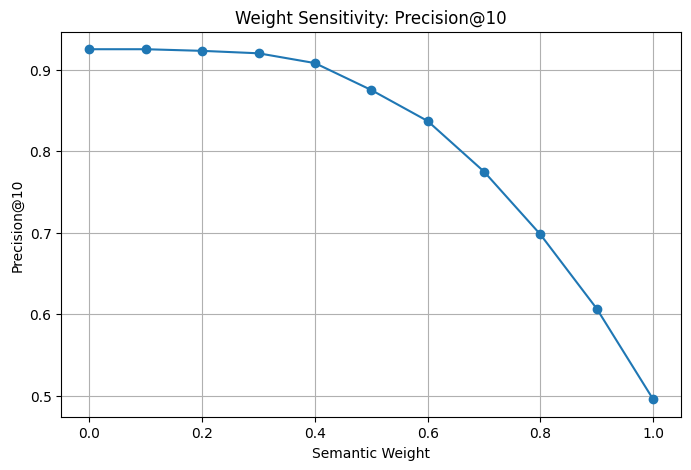

In [ ]:
# ============================================================
# PLOT 1: Precision@10 vs Semantic Weight
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    sensitivity_df["Semantic Weight"],
    sensitivity_df["Precision@10"],
    marker="o"
)

plt.xlabel("Semantic Weight")
plt.ylabel("Precision@10")
plt.title("Weight Sensitivity: Precision@10")

plt.grid(True)
plt.show()

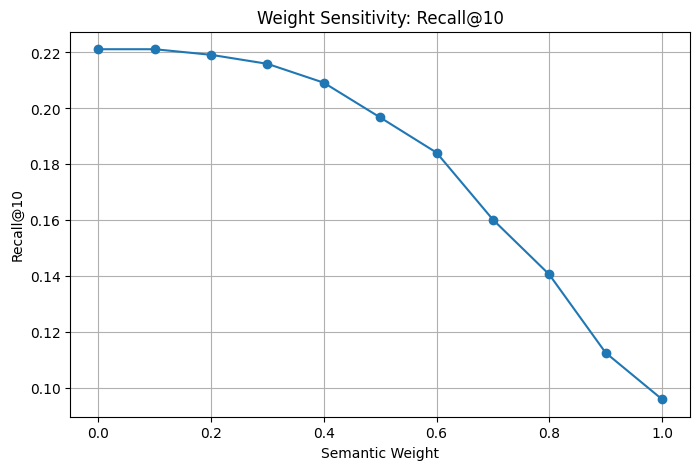

In [ ]:
# ============================================================
# PLOT 2: Recall@10 vs Semantic Weight
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    sensitivity_df["Semantic Weight"],
    sensitivity_df["Recall@10"],
    marker="o"
)

plt.xlabel("Semantic Weight")
plt.ylabel("Recall@10")
plt.title("Weight Sensitivity: Recall@10")

plt.grid(True)
plt.show()

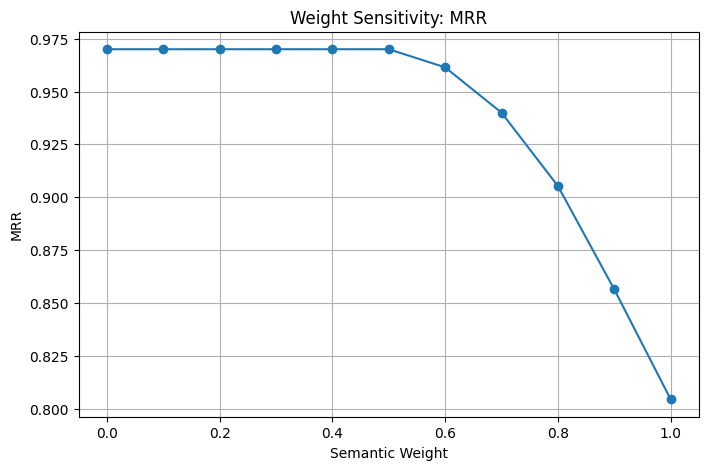

In [ ]:
# ============================================================
# PLOT 3: MRR vs Semantic Weight
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    sensitivity_df["Semantic Weight"],
    sensitivity_df["MRR"],
    marker="o"
)

plt.xlabel("Semantic Weight")
plt.ylabel("MRR")
plt.title("Weight Sensitivity: MRR")

plt.grid(True)
plt.show()

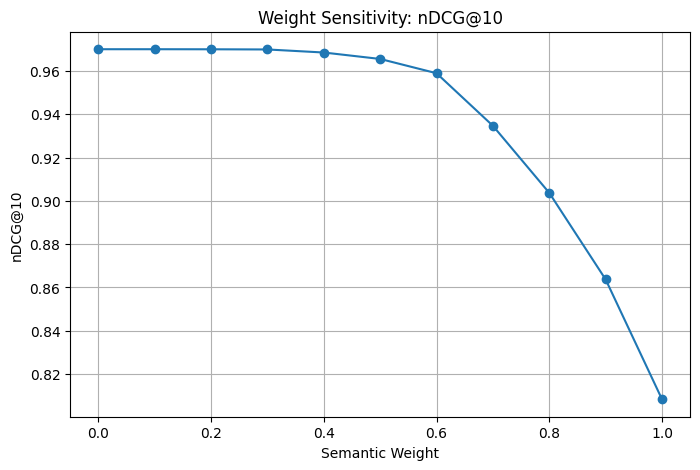

In [ ]:
# ============================================================
# PLOT 4: nDCG@10 vs Semantic Weight
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    sensitivity_df["Semantic Weight"],
    sensitivity_df["nDCG@10"],
    marker="o"
)

plt.xlabel("Semantic Weight")
plt.ylabel("nDCG@10")
plt.title("Weight Sensitivity: nDCG@10")

plt.grid(True)
plt.show()

In [ ]:
# ============================================================
# BEST WEIGHT CONFIGURATIONS
# ============================================================

print("Best configuration by Precision@10:")
display(
    sensitivity_df.loc[
        sensitivity_df["Precision@10"].idxmax()
    ].to_frame().T
)

print("\nBest configuration by Recall@10:")
display(
    sensitivity_df.loc[
        sensitivity_df["Recall@10"].idxmax()
    ].to_frame().T
)

print("\nBest configuration by MRR:")
display(
    sensitivity_df.loc[
        sensitivity_df["MRR"].idxmax()
    ].to_frame().T
)

print("\nBest configuration by nDCG@10:")
display(
    sensitivity_df.loc[
        sensitivity_df["nDCG@10"].idxmax()
    ].to_frame().T
)

Best configuration by Precision@10:


,Semantic Weight,Context Weight,Precision@10,Recall@10,MRR,nDCG@10
0,0.0,1.0,0.925,0.221162,0.97,0.97



Best configuration by Recall@10:


,Semantic Weight,Context Weight,Precision@10,Recall@10,MRR,nDCG@10
0,0.0,1.0,0.925,0.221162,0.97,0.97



Best configuration by MRR:


,Semantic Weight,Context Weight,Precision@10,Recall@10,MRR,nDCG@10
0,0.0,1.0,0.925,0.221162,0.97,0.97



Best configuration by nDCG@10:


,Semantic Weight,Context Weight,Precision@10,Recall@10,MRR,nDCG@10
0,0.0,1.0,0.925,0.221162,0.97,0.97


Resolution Ranking

In [ ]:


resolution_ranking = (
    retrieved
    .groupby("company_response")["hybrid_score"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

resolution_ranking.columns = [
    "resolution",
    "resolution_score"
]

# Normalize into recommendation confidence
total_score = resolution_ranking[
    "resolution_score"
].sum()

resolution_ranking["confidence"] = (
    resolution_ranking["resolution_score"]
    / total_score
)

resolution_ranking["rank"] = (
    resolution_ranking.index + 1
)

display(resolution_ranking)

,resolution,resolution_score,confidence,rank
0,Closed with non-monetary relief,276.862387,0.529845,1
1,Closed with explanation,243.603637,0.466197,2
2,Closed with monetary relief,2.068205,0.003958,3


Top-K Resolution Recommendation

In [ ]:


TOP_K = 3

top_k_resolution = resolution_ranking.head(
    TOP_K
).copy()

print("=" * 65)
print("TOP-K RESOLUTION RECOMMENDATIONS")
print("=" * 65)

for _, row in top_k_resolution.iterrows():

    print(
        f"\nTop {int(row['rank'])}: "
        f"{row['resolution']}"
    )

    print(
        f"Score      : "
        f"{row['resolution_score']:.4f}"
    )

    print(
        f"Confidence : "
        f"{row['confidence'] * 100:.2f}%"
    )

TOP-K RESOLUTION RECOMMENDATIONS

Top 1: Closed with non-monetary relief
Score      : 276.8624
Confidence : 52.98%

Top 2: Closed with explanation
Score      : 243.6036
Confidence : 46.62%

Top 3: Closed with monetary relief
Score      : 2.0682
Confidence : 0.40%


Human-Readable Resolution Guidance

In [ ]:
resolution_guidance = {

    "Closed with monetary relief":
        "Historical similar cases were resolved through monetary relief, refund, reimbursement, or financial adjustment.",

    "Closed with non-monetary relief":
        "Historical similar cases were resolved through non-monetary corrective action or account-related resolution.",

    "Closed with explanation":
        "Historical similar cases were resolved primarily through explanation, clarification, or communication."
}

In [ ]:
top_k_resolution["resolution_guidance"] = (
    top_k_resolution["resolution"]
    .map(resolution_guidance)
)

display(
    top_k_resolution[
        [
            "rank",
            "resolution",
            "confidence",
            "resolution_guidance"
        ]
    ]
)

,rank,resolution,confidence,resolution_guidance
0,1,Closed with non-monetary relief,0.529845,Historical similar cases were resolved through...
1,2,Closed with explanation,0.466197,Historical similar cases were resolved primari...
2,3,Closed with monetary relief,0.003958,Historical similar cases were resolved through...


XAI Explanation

In [ ]:


def explain_resolution(
    retrieved_cases,
    resolution
):

    cases = retrieved_cases[
        retrieved_cases["company_response"]
        == resolution
    ].copy()

    if len(cases) == 0:
        print("No supporting cases found.")
        return

    print("=" * 65)
    print("XAI EXPLANATION")
    print("=" * 65)

    print(
        "\nRecommended Resolution:",
        resolution
    )

    print(
        "\nNumber of supporting cases:",
        len(cases)
    )

    print(
        "\nAverage semantic similarity:",
        round(
            cases["similarity_score"].mean(),
            4
        )
    )

    print(
        "Average context similarity:",
        round(
            cases["context_similarity"].mean(),
            4
        )
    )

    print("\nContextual evidence:")

    for feature in context_weights.keys():

        query_value = str(
            query_row[feature]
        ).strip().lower()

        matching_cases = (
            cases[feature]
            .astype(str)
            .str.strip()
            .str.lower()
            == query_value
        ).sum()

        percentage = (
            matching_cases /
            len(cases)
        ) * 100

        print(
            f"{feature:15s}: "
            f"{percentage:.1f}% matching"
        )

Run XAI for Top Recommendation

In [ ]:
best_resolution = top_k_resolution.iloc[0][
    "resolution"
]

explain_resolution(
    retrieved,
    best_resolution
)

XAI EXPLANATION

Recommended Resolution: Closed with non-monetary relief

Number of supporting cases: 518

Average semantic similarity: 0.5349
Average context similarity: 0.5336

Contextual evidence:
product        : 94.4% matching
sub_product    : 94.2% matching
issue          : 53.5% matching
sub_issue      : 1.0% matching
company        : 49.2% matching
timely         : 100.0% matching


Final Recommendation Display

In [ ]:


print("\n" + "=" * 70)
print("CONSUMER COMPLAINT RESOLUTION RECOMMENDATION")
print("=" * 70)

print("\nComplaint:")
print(query)

print("\nTop Similar Historical Cases:")

display(
    retrieved[
        [
            "complaint_id",
            "similarity_score",
            "context_similarity",
            "hybrid_score",
            "company_response"
        ]
    ].head(5)
)

print("\nRecommended Resolution Pathways:")

display(
    top_k_resolution[
        [
            "rank",
            "resolution",
            "confidence",
            "resolution_guidance"
        ]
    ]
)


CONSUMER COMPLAINT RESOLUTION RECOMMENDATION

Complaint:

I found an unauthorized inquiry
on my credit report that I do not recognize.


Top Similar Historical Cases:


,complaint_id,similarity_score,context_similarity,hybrid_score,company_response
0,9996796,0.822083,1.0,0.875458,Closed with explanation
1,9997724,0.785892,1.0,0.850124,Closed with explanation
2,9998541,0.779472,1.0,0.845631,Closed with explanation
3,9996749,0.777194,1.0,0.844036,Closed with non-monetary relief
4,9998392,0.796845,0.9,0.827791,Closed with explanation



Recommended Resolution Pathways:


,rank,resolution,confidence,resolution_guidance
0,1,Closed with non-monetary relief,0.529845,Historical similar cases were resolved through...
1,2,Closed with explanation,0.466197,Historical similar cases were resolved primari...
2,3,Closed with monetary relief,0.003958,Historical similar cases were resolved through...


Semantic vs Context vs Hybrid Score

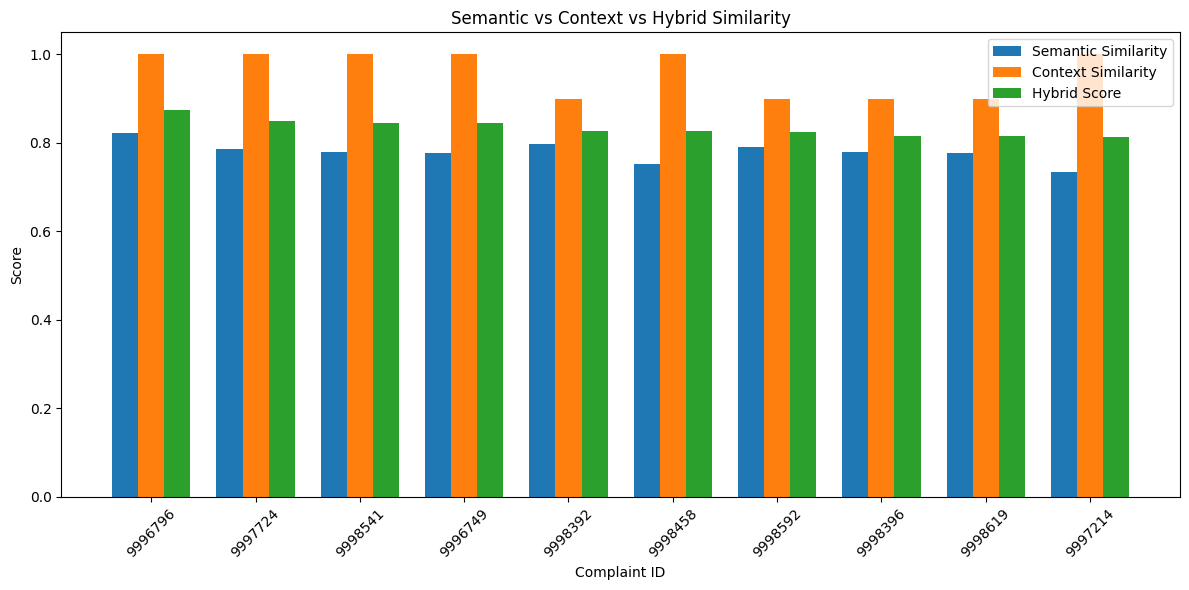

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Take top 10 retrieved cases
plot_df = retrieved.head(10).copy()

labels = plot_df["complaint_id"].astype(str)

x = np.arange(len(labels))
width = 0.25

plt.figure(figsize=(12, 6))

plt.bar(
    x - width,
    plot_df["similarity_score"],
    width,
    label="Semantic Similarity"
)

plt.bar(
    x,
    plot_df["context_similarity"],
    width,
    label="Context Similarity"
)

plt.bar(
    x + width,
    plot_df["hybrid_score"],
    width,
    label="Hybrid Score"
)

plt.xlabel("Complaint ID")
plt.ylabel("Score")
plt.title("Semantic vs Context vs Hybrid Similarity")
plt.xticks(x, labels, rotation=45)
plt.ylim(0, 1.05)
plt.legend()

plt.tight_layout()
plt.show()

Context-Aware Ranking of Top-10 Complaints

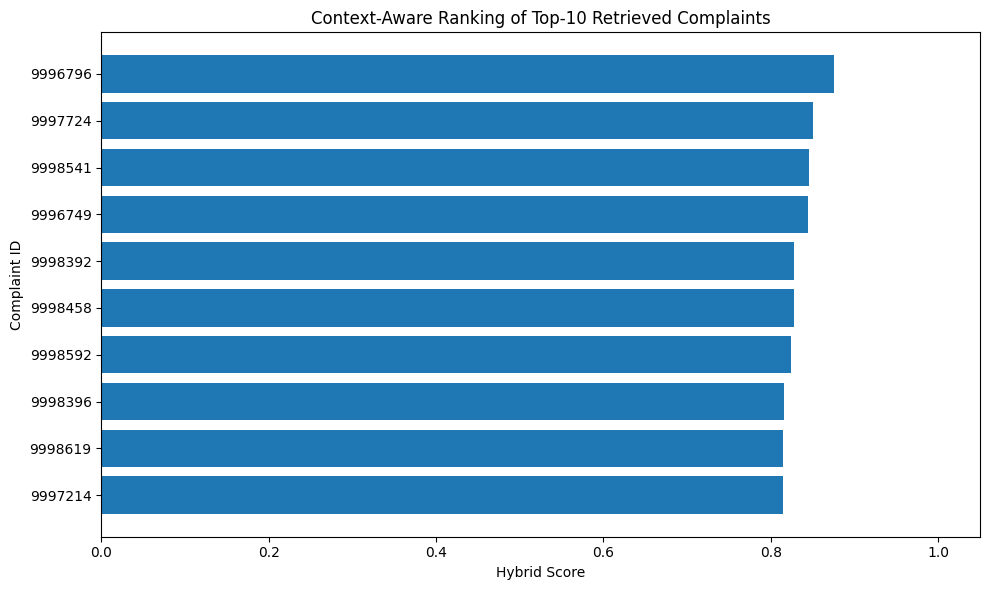

In [ ]:
import matplotlib.pyplot as plt

rank_df = retrieved.head(10).sort_values(
    "hybrid_score",
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    rank_df["complaint_id"].astype(str),
    rank_df["hybrid_score"]
)

plt.xlabel("Hybrid Score")
plt.ylabel("Complaint ID")
plt.title("Context-Aware Ranking of Top-10 Retrieved Complaints")
plt.xlim(0, 1.05)

plt.tight_layout()
plt.show()

Resolution Distribution

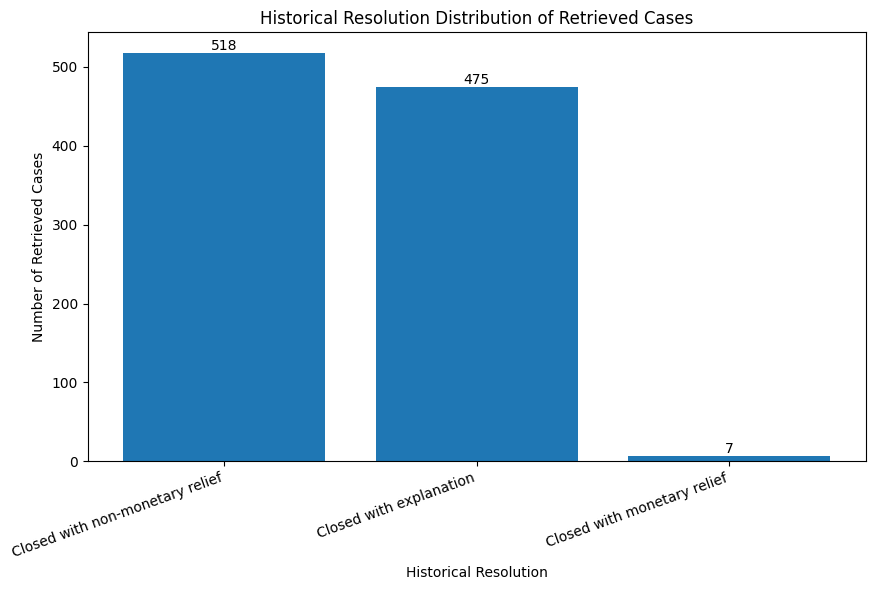

In [ ]:
import matplotlib.pyplot as plt

resolution_counts = (
    retrieved["company_response"]
    .value_counts()
)

plt.figure(figsize=(9, 6))

bars = plt.bar(
    resolution_counts.index,
    resolution_counts.values
)

plt.xlabel("Historical Resolution")
plt.ylabel("Number of Retrieved Cases")
plt.title("Historical Resolution Distribution of Retrieved Cases")

plt.xticks(
    rotation=20,
    ha="right"
)

# Display count on top of each bar
for bar in bars:

    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        str(int(height)),
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

Top-K Resolution Recommendation

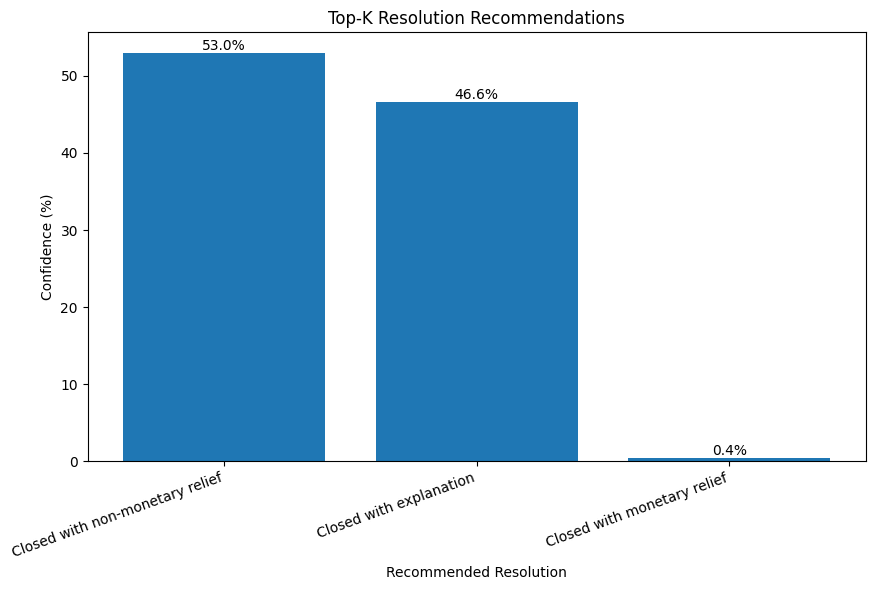

In [ ]:
import matplotlib.pyplot as plt

rec_df = top_k_resolution.copy()

plt.figure(figsize=(9, 6))

bars = plt.bar(
    rec_df["resolution"],
    rec_df["confidence"] * 100
)

plt.xlabel("Recommended Resolution")
plt.ylabel("Confidence (%)")
plt.title("Top-K Resolution Recommendations")

plt.xticks(
    rotation=20,
    ha="right"
)

# Display confidence percentage
for bar in bars:

    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{height:.1f}%",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

XAI Context Evidence

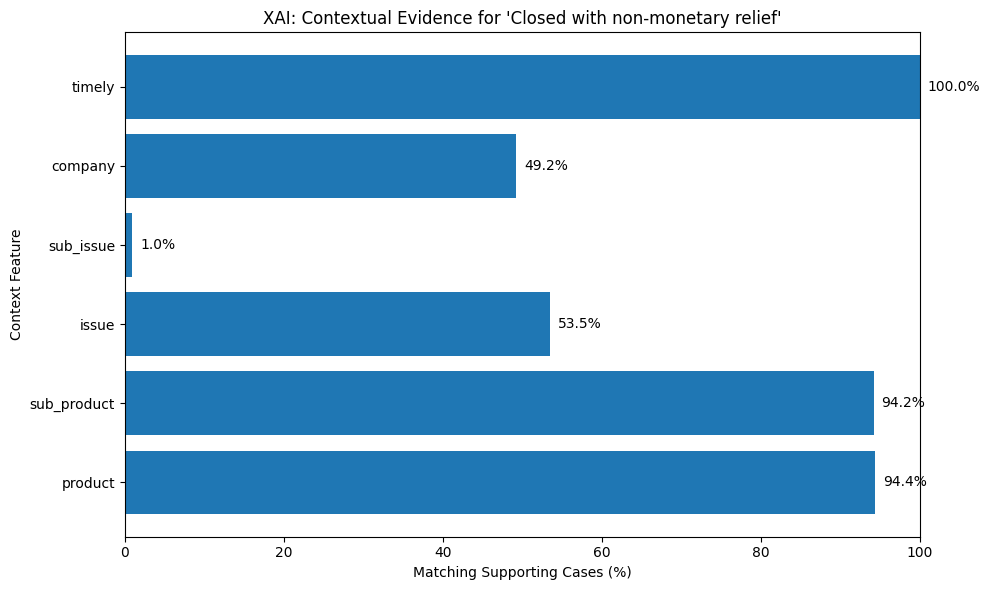

In [ ]:
import matplotlib.pyplot as plt

best_resolution = top_k_resolution.iloc[0]["resolution"]

supporting_cases = retrieved[
    retrieved["company_response"] == best_resolution
].copy()

features = [
    "product",
    "sub_product",
    "issue",
    "sub_issue",
    "company",
    "timely"
]

match_percentages = []

for feature in features:

    query_value = str(
        query_row[feature]
    ).strip().lower()

    matches = (
        supporting_cases[feature]
        .astype(str)
        .str.strip()
        .str.lower()
        == query_value
    )

    match_percentages.append(
        matches.mean() * 100
    )

plt.figure(figsize=(10, 6))

bars = plt.barh(
    features,
    match_percentages
)

plt.xlabel("Matching Supporting Cases (%)")
plt.ylabel("Context Feature")
plt.title(
    f"XAI: Contextual Evidence for '{best_resolution}'"
)

plt.xlim(0, 100)

for bar, value in zip(bars, match_percentages):

    plt.text(
        value + 1,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.1f}%",
        va="center"
    )

plt.tight_layout()
plt.show()

,similarity_score,context_similarity,Semantic_Contribution,Context_Contribution,Calculated_Hybrid_Score
0,0.8221,1.0,0.5755,0.30,0.8755
1,0.7859,1.0,0.5501,0.30,0.8501
2,0.7795,1.0,0.5456,0.30,0.8456
3,0.7772,1.0,0.5440,0.30,0.8440
4,0.7968,0.9,0.5578,0.27,0.8278
5,0.7534,1.0,0.5274,0.30,0.8274
6,0.7910,0.9,0.5537,0.27,0.8237
7,0.7794,0.9,0.5456,0.27,0.8156
8,0.7783,0.9,0.5448,0.27,0.8148
9,0.7351,1.0,0.5146,0.30,0.8146


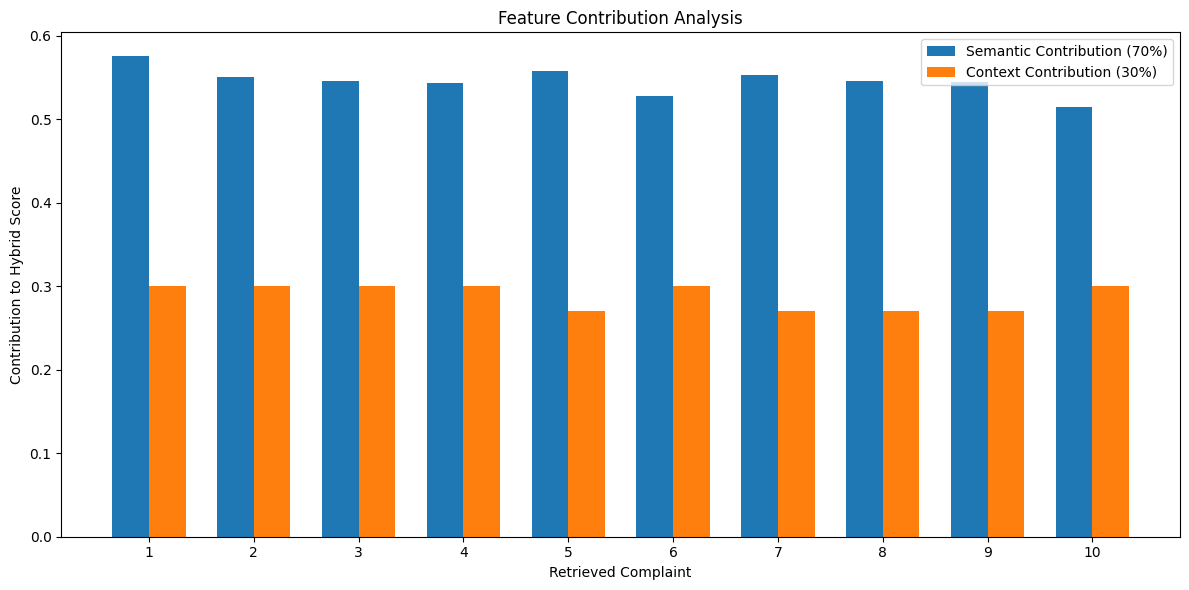

In [ ]:

# ============================================================
# FEATURE CONTRIBUTION ANALYSIS
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# 1. Select the top 10 retrieved complaints
contribution_df = retrieved.head(10).copy()

# 2. Calculate individual feature contributions
contribution_df["Semantic_Contribution"] = (
    0.70 * contribution_df["similarity_score"]
)

contribution_df["Context_Contribution"] = (
    0.30 * contribution_df["context_similarity"]
)

# 3. Calculate the final hybrid score
contribution_df["Calculated_Hybrid_Score"] = (
    contribution_df["Semantic_Contribution"]
    + contribution_df["Context_Contribution"]
)

# 4. Display the feature contribution table
display(
    contribution_df[
        [
            "similarity_score",
            "context_similarity",
            "Semantic_Contribution",
            "Context_Contribution",
            "Calculated_Hybrid_Score"
        ]
    ].round(4)
)

# ============================================================
# VISUALIZATION
# ============================================================

x = np.arange(len(contribution_df))
width = 0.35

plt.figure(figsize=(12, 6))

plt.bar(
    x - width / 2,
    contribution_df["Semantic_Contribution"],
    width,
    label="Semantic Contribution (70%)"
)

plt.bar(
    x + width / 2,
    contribution_df["Context_Contribution"],
    width,
    label="Context Contribution (30%)"
)

plt.xlabel("Retrieved Complaint")
plt.ylabel("Contribution to Hybrid Score")
plt.title("Feature Contribution Analysis")
plt.xticks(x, range(1, len(contribution_df) + 1))
plt.legend()
plt.tight_layout()
plt.show()
